In [1]:
import numpy as np
# إصلاح للتوافق مع الكود القديم الذي يستخدم np.bool
if not hasattr(np, 'bool'):
    np.bool = bool

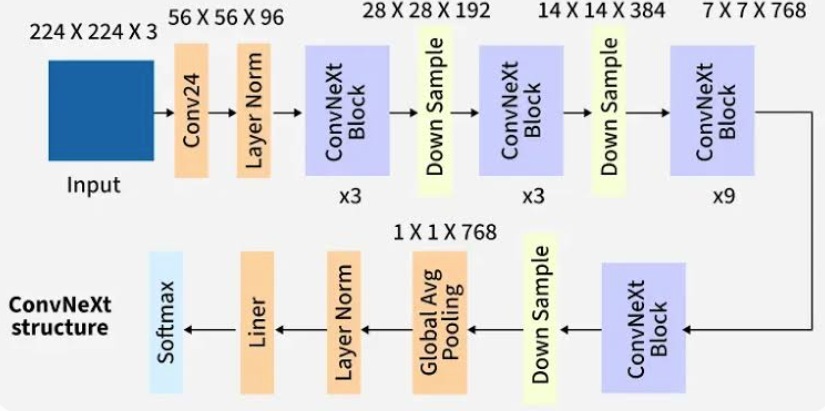

In [2]:
import os
import random
import numpy as np
import pandas as pd
import cv2
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import itertools

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.efficientnet import preprocess_input as ef_preprocess

# إصلاح np.bool لـ numpy 2.x
if not hasattr(np, 'bool'):
    np.bool = bool

# Albumentations for strong augmentations
import albumentations as A
from albumentations.core.composition import OneOf

# For handcrafted features
from skimage.feature import local_binary_pattern
from skimage.color import rgb2gray

# For GradCAM
from tensorflow.keras.models import Model
import matplotlib.cm as cm

# ================================================================
# ⚙️ SEED - غيّر هذا الرقم فقط في كل تجربة (يدوياً)
# ================================================================
RANDOM_STATE = 2026  

os.environ['PYTHONHASHSEED'] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ---------------------------
# User-configurable params
# ---------------------------
DATASET_PATH_1 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
DATASET_PATH_2 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2'
METADATA_CSV = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv'

IMG_SIZE = (224,224)   # 
BATCH_SIZE = 32
# RANDOM_STATE معرّف في الأعلى الآن

TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-6

USE_HANCRAFTED = True
EPOCHS = 30

# ================================================================
# Load metadata
# ================================================================
meta_df = pd.read_csv(METADATA_CSV)
imageid_to_label = dict(zip(meta_df['image_id'], meta_df['dx']))

image_files_1 = sorted(os.listdir(DATASET_PATH_1))
image_files_2 = sorted(os.listdir(DATASET_PATH_2))
all_image_files = image_files_1 + image_files_2

rows = []
for fname in tqdm(all_image_files, desc='Listing images'):
    image_id = os.path.splitext(fname)[0]
    label = imageid_to_label.get(image_id)
    if label is None: continue
    if fname in image_files_1:
        full = os.path.join(DATASET_PATH_1, fname)
    else:
        full = os.path.join(DATASET_PATH_2, fname)
    rows.append((full, label))

df = pd.DataFrame(rows, columns=['path','label'])
print("Total images found:", len(df))
print("Label distribution:\n", df['label'].value_counts())

# Encode labels
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))

# ================================================================
# Stratified split train/val/test
# ================================================================
train_and_val, test_df = train_test_split(df, test_size=TEST_RATIO, stratify=df['label_enc'], random_state=RANDOM_STATE)
relative_val_ratio = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_df, val_df = train_test_split(train_and_val, test_size=relative_val_ratio, stratify=train_and_val['label_enc'], random_state=RANDOM_STATE)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))

# ================================================================
# Handcrafted features
# ================================================================
def compute_lbp(img_gray, P=8, R=1):
    lbp = local_binary_pattern(img_gray, P=P, R=R, method='uniform')
    n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(lbp, bins=n_bins, range=(0, n_bins), density=True)
    return hist

def color_histogram(img, n_bins=16):
    chans = cv2.split(img)
    feats = []
    for ch in chans:
        hist, _ = np.histogram(ch, bins=n_bins, range=(0,256), density=True)
        feats.extend(hist)
    return np.array(feats)

def extract_handcrafted_features(image_path):
    img = cv2.imread(image_path)
    if img is None: return np.zeros(16 + 16*3)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_small = cv2.resize(img, (128,128))
    gray = rgb2gray(img_small)
    lbp = compute_lbp(gray, P=8, R=1)
    ch = color_histogram(img_small, n_bins=16)
    feat = np.concatenate([lbp, ch])
    return feat

if USE_HANCRAFTED:
    print("Computing handcrafted features...")
    def compute_features_for_df(df_in):
        return np.vstack([extract_handcrafted_features(p) for p in tqdm(df_in['path'].values)])
    feats_train = compute_features_for_df(train_df)
    feats_val = compute_features_for_df(val_df)
    feats_test = compute_features_for_df(test_df)
else:
    feats_train = feats_val = feats_test = None

# ================================================================
# Albumentations augmentation
# ================================================================
IMG_SIZE = 224

train_transform = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.8, 1.0)),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=45, p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=0.5)
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE)
])


def load_image(path, augment=None):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if augment:
        img = augment(image=img)["image"]
    else:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return ef_preprocess(img.astype(np.float32))

# ================================================================
# Balanced generator
# ================================================================
class BalancedDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, df, features=None, batch_size=32, augment=None, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.features = features
        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()
    def __len__(self): return int(np.ceil(len(self.df) / self.batch_size))
    def on_epoch_end(self):
        if self.shuffle:
            np.random.seed(RANDOM_STATE)   # <-- أضفنا هذا فقط لضمان SEED ثابت
            np.random.shuffle(self.indices)
    def __getitem__(self, idx):
        batch_idx = self.indices[idx*self.batch_size:(idx+1)*self.batch_size]
        batch_paths = self.df.loc[batch_idx, "path"].values
        batch_labels = self.df.loc[batch_idx, "label_enc"].values
        imgs, hands = [], []
        for i, path in enumerate(batch_paths):
            img = load_image(path, augment=self.augment)
            imgs.append(img)
            if self.features is not None:
                hands.append(self.features[batch_idx[i]])
        imgs = np.stack(imgs, axis=0)
        y = tf.keras.utils.to_categorical(batch_labels, num_classes=num_classes)
        if self.features is not None:
            hands = np.vstack(hands)
            return (imgs, hands), y
        else:
            return imgs, y

train_gen = BalancedDataGenerator(train_df, feats_train, batch_size=BATCH_SIZE, augment=train_transform)
val_gen = BalancedDataGenerator(val_df, feats_val, batch_size=BATCH_SIZE, augment=val_transform, shuffle=False)
test_gen = BalancedDataGenerator(test_df, feats_test, batch_size=BATCH_SIZE, augment=val_transform, shuffle=False)

# ================================================================
# Model
# ================================================================
def build_model(num_classes, use_handcrafted=False, handcrafted_dim=None):
    img_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image_input')
    base = ConvNeXtTiny(include_top=False, input_tensor=img_input, weights='imagenet')
    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    if use_handcrafted and handcrafted_dim is not None:
        hand_input = layers.Input(shape=(handcrafted_dim,), name='hand_input')
        h = layers.BatchNormalization()(hand_input)
        h = layers.Dense(64, activation='relu')(h)
        combined = layers.Concatenate()([x, h])
        x = layers.Dense(256, activation='relu')(combined)
        x = layers.Dropout(0.3)(x)
        out = layers.Dense(num_classes, activation='softmax')(x)
        model = models.Model(inputs=[img_input, hand_input], outputs=out)
    else:
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.4)(x)
        out = layers.Dense(num_classes, activation='softmax')(x)
        model = models.Model(inputs=img_input, outputs=out)
    return model, base

handcraft_dim = feats_train.shape[1] if USE_HANCRAFTED else None
model, base_model = build_model(num_classes, USE_HANCRAFTED, handcraft_dim)
model.summary()

for layer in base_model.layers:
    layer.trainable = True

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# ================================================================
# Train
# ================================================================
checkpoint_path = f"best_model_seed{RANDOM_STATE}.h5"   # <-- يضيف رقم الـ SEED لاسم الملف
cb = [
    callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

history = model.fit(train_gen,
                    validation_data=val_gen,
                    epochs=EPOCHS,
                    callbacks=cb)


Listing images: 100%|██████████| 10015/10015 [00:00<00:00, 18375.26it/s]


Total images found: 10015
Label distribution:
 label
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Train: 7009 Val: 1503 Test: 1503
Computing handcrafted features...


  0%|          | 0/7009 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/skimage/feature/texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(
100%|██████████| 1503/1503 [00:34<00:00, 42.95it/s]
/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
I0000 00:00:1792310379.178955      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792310379.182779      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB me

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_4"

...


Epoch 19: finished saving model to best_model_seed2026.h5
110/110 ━━━━━━━━━━━━━━━━━━━━ 169s 2s/step - accuracy: 0.9769 - loss: 0.0689 - val_accuracy: 0.9122 - val_loss: 0.3256 - learning_rate: 5.0000e-05
Epoch 20/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9815 - loss: 0.0579
Epoch 20: val_accuracy did not improve from 0.91218
110/110 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9796 - loss: 0.0579 - val_accuracy: 0.9049 - val_loss: 0.3972 - learning_rate: 5.0000e-05
Epoch 21/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9813 - loss: 0.0475
Epoch 21: val_accuracy did not improve from 0.91218
110/110 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9825 - loss: 0.0495 - val_accuracy: 0.9029 - val_loss: 0.3867 - learning_rate: 5.0000e-05
Epoch 22/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9851 - loss: 0.0419
Epoch 22: val_accuracy did not improve from 0.91218

Epoch 22: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
110/110 ━━━


Epoch 25: finished saving model to best_model_seed2026.h5
110/110 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9879 - loss: 0.0366 - val_accuracy: 0.9128 - val_loss: 0.3842 - learning_rate: 2.5000e-05
Epoch 26/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9918 - loss: 0.0238
Epoch 26: val_accuracy did not improve from 0.91284
110/110 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9912 - loss: 0.0277 - val_accuracy: 0.9115 - val_loss: 0.3915 - learning_rate: 2.5000e-05
Epoch 27/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9912 - loss: 0.0256
Epoch 27: val_accuracy did not improve from 0.91284

Epoch 27: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.
110/110 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9914 - loss: 0.0263 - val_accuracy: 0.9069 - val_loss: 0.4127 - learning_rate: 2.5000e-05
Epoch 28/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9926 - loss: 0.0211
Epoch 28: val_accuracy improved from 0.91284 to 0.91816, saving


Epoch 28: finished saving model to best_model_seed2026.h5
110/110 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9929 - loss: 0.0203 - val_accuracy: 0.9182 - val_loss: 0.3651 - learning_rate: 1.2500e-05
Epoch 29/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9934 - loss: 0.0197
Epoch 29: val_accuracy improved from 0.91816 to 0.91949, saving model to best_model_seed2026.h5



Epoch 29: finished saving model to best_model_seed2026.h5
110/110 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9932 - loss: 0.0218 - val_accuracy: 0.9195 - val_loss: 0.3621 - learning_rate: 1.2500e-05
Epoch 30/30
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9956 - loss: 0.0124
Epoch 30: val_accuracy improved from 0.91949 to 0.92149, saving model to best_model_seed2026.h5



Epoch 30: finished saving model to best_model_seed2026.h5
110/110 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9949 - loss: 0.0153 - val_accuracy: 0.9215 - val_loss: 0.3636 - learning_rate: 1.2500e-05
Restoring model weights from the end of the best epoch: 30.


2026-10-18 09:25:18.106118: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 09:25:18.241783: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Test Accuracy: 92.61%
Classification Report:
               precision    recall  f1-score   support

       akiec     0.7736    0.8367    0.8039        49
         bcc     0.8846    0.8961    0.8903        77
         bkl     0.8933    0.8121    0.8508       165
          df     0.8750    0.8235    0.8485        17
         mel     0.9023    0.7186    0.8000       167
          nv     0.9440    0.9881    0.9655      1006
        vasc     1.0000    0.9091    0.9524        22

    accuracy                         0.9261      1503
   macro avg     0.8961    0.8549    0.8731      1503
weighted avg     0.9252    0.9261    0.9239      1503



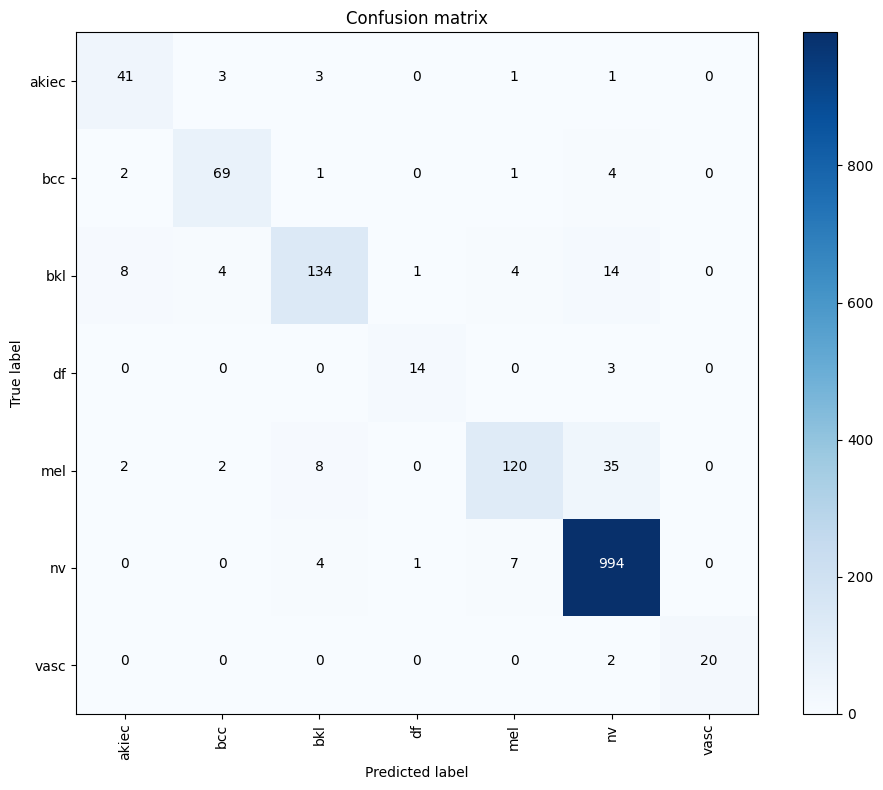

In [3]:
# ================================================================
# Evaluation - Safe Version
# ================================================================
import itertools
def get_preds_safe(generator):
    """Collect predictions from generator safely"""
    preds, labels = [], []
    n_batches = len(generator)
    
    for i in range(n_batches):
        try:
            X, y = generator[i]
            if isinstance(X, tuple):
                p = model.predict(X, verbose=0)
            else:
                p = model.predict(X, verbose=0)
            preds.append(p)
            labels.append(y)
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not preds:
        return np.array([]), np.array([])
    
    return np.vstack(preds), np.vstack(labels)

preds, true = get_preds_safe(test_gen)
pred_labels = np.argmax(preds, axis=1)
true_labels = np.argmax(true, axis=1)

acc = accuracy_score(true_labels, pred_labels)
print(f"Test Accuracy: {acc*100:.2f}%")
print("Classification Report:\n", classification_report(true_labels, pred_labels, target_names=le.classes_, digits=4))

cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(10,8))
plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.colorbar()
plt.xticks(np.arange(len(le.classes_)), le.classes_, rotation=90)
plt.yticks(np.arange(len(le.classes_)), le.classes_)
thresh = cm.max() / 2
for i,j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j,i,cm[i,j], ha="center", color="white" if cm[i,j]>thresh else "black")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()


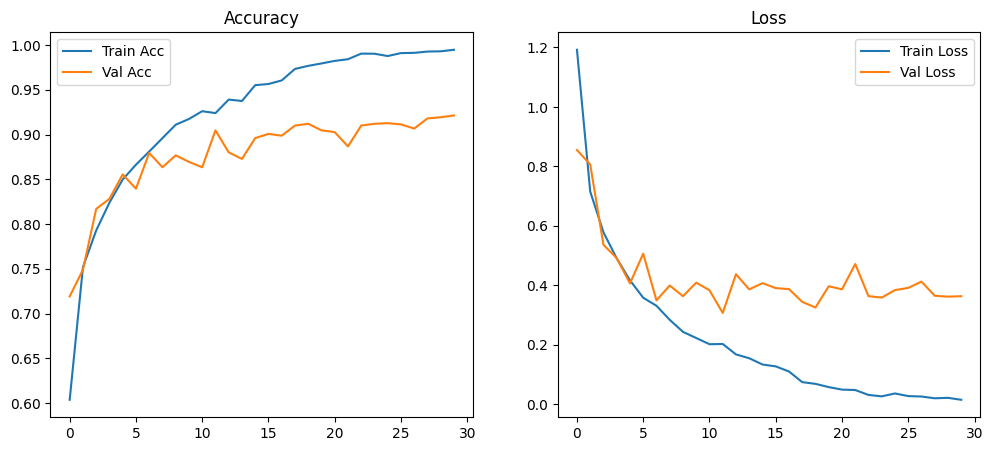

In [4]:
# ================================================================
# Training curves
# ================================================================
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Accuracy")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.legend()
plt.show()

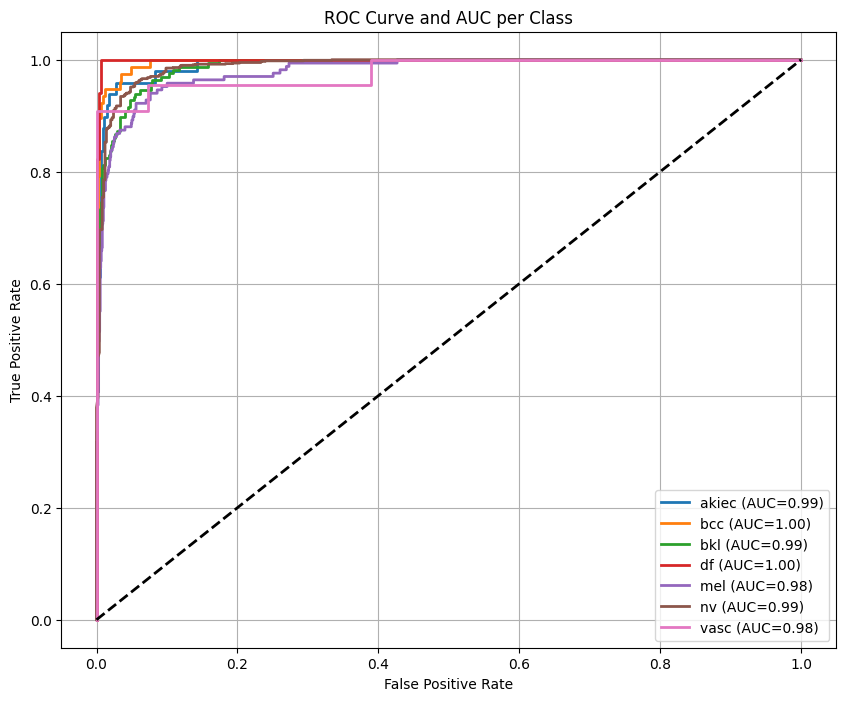

AUC for akiec: 0.9918
AUC for bcc: 0.9963
AUC for bkl: 0.9883
AUC for df: 0.9992
AUC for mel: 0.9794
AUC for nv: 0.9894
AUC for vasc: 0.9790
weighted-average AUC: 0.9953


In [5]:
# ================================================================
# ROC Curves - Safe Version
# ================================================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def collect_predictions_for_roc(generator, model, num_batches=None):
    """Collect predictions from generator safely for ROC"""
    y_true_list = []
    y_pred_list = []
    
    n_batches = len(generator)
    if num_batches is not None:
        n_batches = min(n_batches, n_batches)
    
    if n_batches == 0:
        print(" Warning: Generator has no batches!")
        return np.array([]), np.array([])
    
    for i in range(n_batches):
        try:
            batch_x, batch_y = generator[i]
            
            if isinstance(batch_x, tuple):
                batch_pred = model.predict(batch_x, verbose=0)
            else:
                batch_pred = model.predict(batch_x, verbose=0)
            
            y_true_list.append(batch_y)
            y_pred_list.append(batch_pred)
            
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not y_true_list:
        print(" No predictions collected!")
        return np.array([]), np.array([])
    
    return np.concatenate(y_true_list, axis=0), np.concatenate(y_pred_list, axis=0)

y_true, y_pred = collect_predictions_for_roc(test_gen, model)

if y_true.size == 0 or y_pred.size == 0:
    print(" Failed to collect predictions, skipping ROC Curves")
else:
    if y_true.ndim == 2:
        y_true_indices = np.argmax(y_true, axis=1)
    else:
        y_true_indices = y_true

    n_classes = y_pred.shape[1]
    class_names = le.classes_

    y_true_bin = label_binarize(y_true_indices, classes=range(n_classes))

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fpr["weighted"], tpr["weighted"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
    roc_auc["weighted"] = auc(fpr["weighted"], tpr["weighted"])

    plt.figure(figsize=(10, 8))
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], lw=2, label=f"{class_names[i]} (AUC={roc_auc[i]:.2f})")

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve and AUC per Class")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    for i in range(n_classes):
        print(f"AUC for {class_names[i]}: {roc_auc[i]:.4f}")
    print(f"weighted-average AUC: {roc_auc['weighted']:.4f}")

In [6]:
# ================================================================
# Complete Metrics
# ================================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

precision = precision_score(true_labels, pred_labels, average="weighted")
sensitivity = recall_score(true_labels, pred_labels, average="weighted")
f1 = f1_score(true_labels, pred_labels, average="weighted")

cm = confusion_matrix(true_labels, pred_labels)
TN = []
FP = []
for i in range(len(cm)):
    tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
    fp = np.sum(cm[:, i]) - cm[i, i]
    TN.append(tn)
    FP.append(fp)
specificity = np.mean(np.array(TN) / (np.array(TN) + np.array(FP)))

auc_score = roc_auc_score(true_labels, preds, multi_class="ovr", average="weighted")

print("="*50)
print(" COMPLETE METRICS SUMMARY")
print("="*50)
print(f" Accuracy    : {acc*100:.2f}%")
print(f" Specificity : {specificity*100:.2f}%")
print(f" Precision   : {precision*100:.2f}%")
print(f" Sensitivity : {sensitivity*100:.2f}%")
print(f" F1 Score    : {f1*100:.2f}%")
print("="*50)

 COMPLETE METRICS SUMMARY
 Accuracy    : 92.61%
 Specificity : 97.77%
 Precision   : 92.52%
 Sensitivity : 92.61%
 F1 Score    : 92.39%


In [7]:
# ================================================================
# 📊 إحصائيات الـ Augmentation قبل وبعد لكل فئة
# ================================================================
def augmentation_statistics(train_df, train_gen, epochs, batch_size, le):
    """
    حساب عدد الصور قبل وبعد الـ Augmentation لكل فئة.
    """
    print("\n" + "=" * 70)
    print("📊 إحصائيات الـ Augmentation (قبل وبعد) لكل فئة")
    print("=" * 70)
    
    # 1. العدد الأصلي لكل فئة (قبل الـ Augmentation)
    original_counts = train_df['label'].value_counts().reindex(le.classes_, fill_value=0)
    
    # 2. العدد الفعلي بعد الـ Augmentation
    #    = عدد الصور × عدد الـ Epochs (لأن كل epoch يولّد نسخاً مختلفة)
    n_batches_per_epoch = len(train_gen)
    n_images_per_epoch = n_batches_per_epoch * batch_size
    
    # 3. حساب عدد الصور المولّدة لكل فئة
    #    (نسبة كل فئة × إجمالي الصور المولّدة)
    total_original = len(train_df)
    augmented_counts = {}
    for cls in le.classes_:
        n_original = original_counts[cls]
        # نسبة الفئة في البيانات الأصلية
        proportion = n_original / total_original
        # عدد الصور المولّدة لهذه الفئة = النسبة × إجمالي الصور المولّدة × epochs
        n_augmented = int(proportion * n_images_per_epoch * epochs)
        augmented_counts[cls] = n_augmented
    
    # 4. بناء الجدول
    stats_df = pd.DataFrame({
        'Class': le.classes_,
        'Original (Before Aug)': original_counts.values,
        'Augmented (After Aug)': [augmented_counts[c] for c in le.classes_],
        'Expansion Ratio': [augmented_counts[c] / max(original_counts[c], 1) 
                            for c in le.classes_]
    })
    
    stats_df['Expansion Ratio'] = stats_df['Expansion Ratio'].round(2)
    
    print(stats_df.to_string(index=False))
    print("=" * 70)
    
    # 5. الإجمالي
    total_original_all = original_counts.sum()
    total_augmented_all = sum(augmented_counts.values())
    
    print(f"\n📌 الإجمالي:")
    print(f"   • صور التدريب الأصلية:        {total_original_all:,}")
    print(f"   • إجمالي الصور المولّدة:      {total_augmented_all:,}")
    print(f"   • نسبة التوسيع الكلية:        {total_augmented_all / total_original_all:.2f}×")
    print(f"   • عدد الـ Epochs:              {epochs}")
    print(f"   • عدد الـ Batches لكل Epoch:  {n_batches_per_epoch}")
    print(f"   • حجم الـ Batch:               {batch_size}")
    print("=" * 70)
    
    return stats_df

# استدعِ الدالة
aug_stats = augmentation_statistics(
    train_df=train_df,
    train_gen=train_gen,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    le=le
)

# احفظ الجدول في CSV
aug_stats.to_csv('augmentation_statistics.csv', index=False)
print("\n💾 تم حفظ الجدول في: augmentation_statistics.csv")


📊 إحصائيات الـ Augmentation (قبل وبعد) لكل فئة
Class  Original (Before Aug)  Augmented (After Aug)  Expansion Ratio
akiec                    229                   6900            30.13
  bcc                    360                  10847            30.13
  bkl                    769                  23172            30.13
   df                     80                   2410            30.12
  mel                    779                  23473            30.13
   nv                   4693                 141412            30.13
 vasc                     99                   2983            30.13

📌 الإجمالي:
   • صور التدريب الأصلية:        7,009
   • إجمالي الصور المولّدة:      211,197
   • نسبة التوسيع الكلية:        30.13×
   • عدد الـ Epochs:              30
   • عدد الـ Batches لكل Epoch:  110
   • حجم الـ Batch:               64

💾 تم حفظ الجدول في: augmentation_statistics.csv



 GradCAM Visualization

 Model Layers (for GradCAM):
----------------------------------------
   1: convnext_tiny_prestem_normalization - Normalization
   2: convnext_tiny_stem - Sequential
   3: convnext_tiny_stage_0_block_0_depthwise_conv - Conv2D
   4: convnext_tiny_stage_0_block_0_layernorm - LayerNormalization
   5: convnext_tiny_stage_0_block_0_pointwise_conv_1 - Dense
   6: convnext_tiny_stage_0_block_0_gelu - Activation
   7: convnext_tiny_stage_0_block_0_pointwise_conv_2 - Dense
   8: convnext_tiny_stage_0_block_0_layer_scale - LayerScale
   9: convnext_tiny_stage_0_block_0_identity - Activation
   10: convnext_tiny_stage_0_block_1_depthwise_conv - Conv2D
   ... and more

 Testing GradCAM on a sample image
 Image: ISIC_0032490.jpg

 Trying layer: Auto-detect
 Using layer: convnext_tiny_stage_3_block_2_identity
 Cannot generate GradCAM: Layer "functional_5" expects 2 input(s), but it received 1 input tensors. Inputs received: [array([[[[221., 151., 178.],
         [220., 151.,

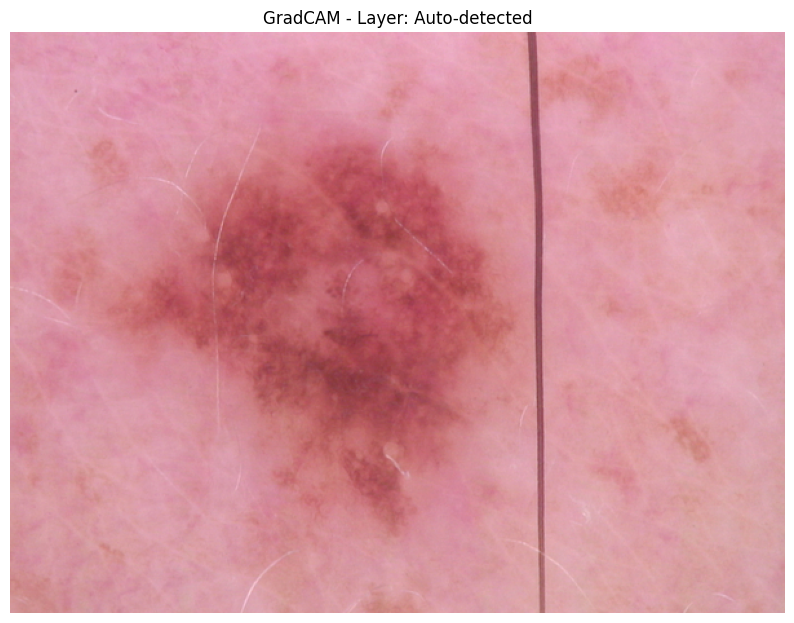


 GradCAM Grid on multiple images
 Using layer: convnext_tiny_stage_3_block_2_identity
 Cannot generate GradCAM: Layer "functional_6" expects 2 input(s), but it received 1 input tensors. Inputs received: [array([[[[ 7.,  3.,  7.],
         [10.,  5.,  9.],
         [11.,  6.,  9.],
         ...,
         [53., 37., 50.],
         [45., 32., 47.],
         [39., 28., 40.]],

        [[10.,  4.,  8.],
         [10.,  6.,  9.],
         [12.,  7., 12.],
         ...,
         [54., 42., 54.],
         [48., 35., 48.],
         [43., 31., 44.]],

        [[11.,  5.,  9.],
         [ 9.,  7., 11.],
         [11.,  7.,  8.],
         ...,
         [57., 45., 57.],
         [52., 38., 55.],
         [45., 32., 47.]],

        ...,

        [[56., 34., 50.],
         [59., 44., 58.],
         [68., 51., 67.],
         ...,
         [85., 67., 84.],
         [80., 60., 77.],
         [73., 53., 75.]],

        [[47., 33., 45.],
         [53., 40., 54.],
         [63., 47., 63.],
         ...,
 

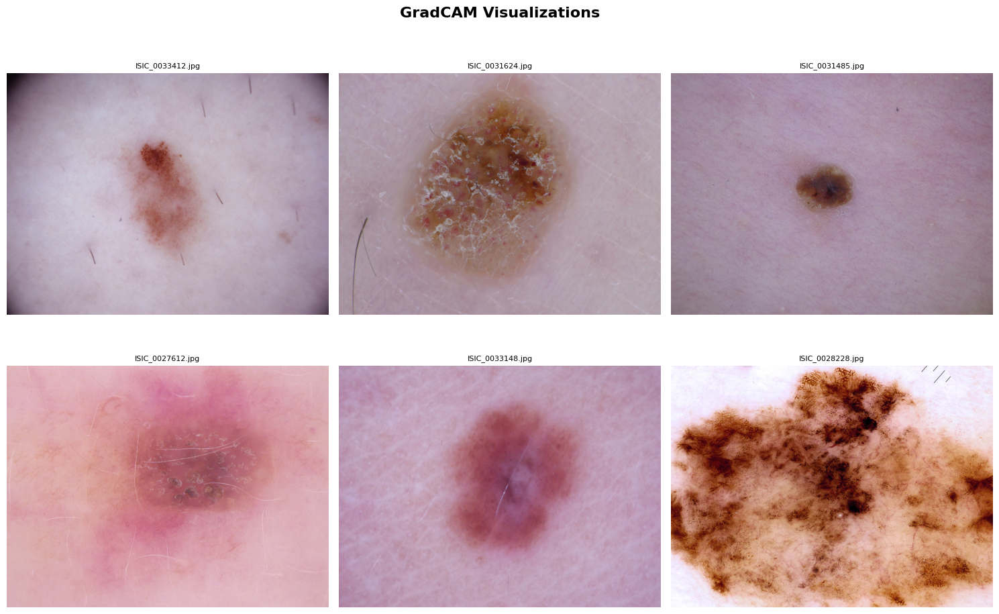


 GradCAM visualization complete!

 GradCAM with Handcrafted Features
 Using layer: convnext_tiny_stage_3_block_2_identity


/usr/local/lib/python3.13/dist-packages/skimage/feature/texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


2026-10-18 09:26:15.625459: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 09:26:15.777992: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 09:26:15.910267: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


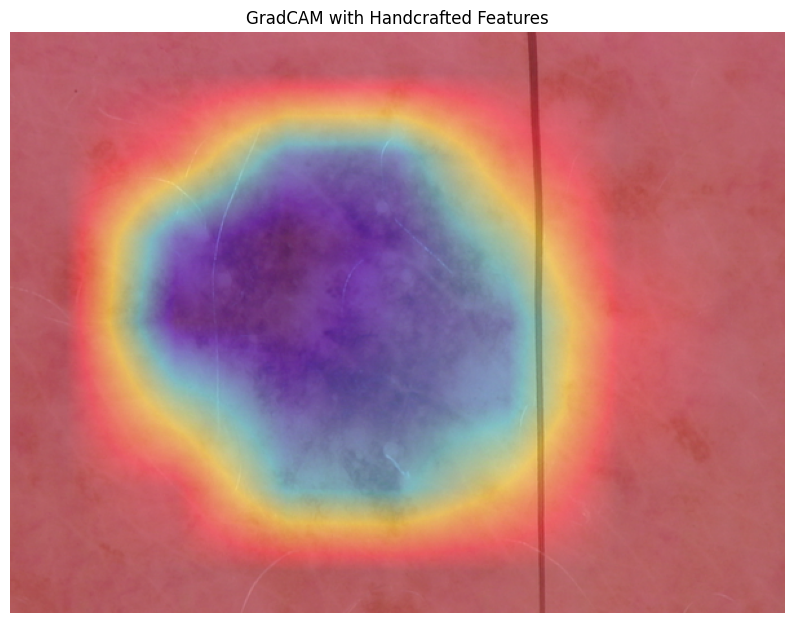

In [8]:
# ================================================================
# Cell 19: GradCAM Functions (Enhanced)
# ================================================================
from tensorflow.keras.applications.convnext import preprocess_input as convnext_preprocess
def get_gradcam_heatmap(model, img_array, layer_name=None, pred_index=None, hand_features=None):
    """
    Generate GradCAM heatmap with automatic layer selection
    """
    # If no layer is specified, find the best Conv layer
    if layer_name is None:
        for layer in reversed(model.layers):
            # Look for suitable Conv layers
            if 'conv' in layer.name and 'convnext' in layer.name:
                layer_name = layer.name
                break
            elif 'conv' in layer.name and 'block' in layer.name:
                layer_name = layer.name
                break
            elif 'conv2d' in layer.name.lower():
                layer_name = layer.name
                break
        
        # If no layer found, use the last Conv layer
        if layer_name is None:
            for layer in reversed(model.layers):
                if 'conv' in layer.name.lower():
                    layer_name = layer.name
                    break
    
    print(f" Using layer: {layer_name}")
    
    try:
        # Try to create the model with the specified layer
        grad_model = tf.keras.models.Model(
            inputs=model.inputs,
            outputs=[model.get_layer(layer_name).output, model.output]
        )
    except Exception as e:
        print(f" Error with layer {layer_name}: {e}")
        # Try using an alternative layer
        for layer in reversed(model.layers):
            if 'conv' in layer.name.lower():
                try:
                    grad_model = tf.keras.models.Model(
                        inputs=model.inputs,
                        outputs=[layer.output, model.output]
                    )
                    layer_name = layer.name
                    print(f" Using alternative layer: {layer_name}")
                    break
                except:
                    continue
    
    # Prepare inputs
    inputs = [img_array]
    if hand_features is not None:
        inputs.append(hand_features)
    
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(inputs)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        loss = predictions[:, pred_index]
    
    grads = tape.gradient(loss, conv_outputs)
    
    # Process gradients
    if grads is None:
        print(" No gradients found. Using fallback method.")
        # Use alternative method
        heatmap = np.random.rand(7, 7)  # Random size
        return heatmap
    
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    
    # Normalize heatmap
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()


def display_gradcam(img_path, model, layer_name=None, alpha=0.4, hand_features=None):
    """
    Display image with GradCAM overlay with automatic layer detection
    """
    # Load and process image
    img = cv2.imread(img_path)
    if img is None:
        print(f" Cannot read image: {img_path}")
        return None
    
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img_preprocessed = convnext_preprocess(img_resized.astype(np.float32))
    img_array = np.expand_dims(img_preprocessed, axis=0)
    
    try:
        # Try to get the heatmap
        if hand_features is not None:
            heatmap = get_gradcam_heatmap(model, img_array, layer_name, hand_features=hand_features)
        else:
            heatmap = get_gradcam_heatmap(model, img_array, layer_name)
        
        # Resize heatmap to match original image
        heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
        heatmap_resized = np.uint8(255 * heatmap_resized)
        heatmap_colored = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)
        
        # Overlay image with heatmap
        superimposed_img = cv2.addWeighted(img, 1 - alpha, heatmap_colored, alpha, 0)
        return superimposed_img
    
    except Exception as e:
        print(f" Cannot generate GradCAM: {e}")
        print(" Attempting to find suitable layers...")
        
        # Display all available layers
        print("\n Available layers in model:")
        for i, layer in enumerate(model.layers):
            if 'conv' in layer.name.lower():
                print(f"   {i}: {layer.name} - {layer.__class__.__name__}")
        
        return img


def display_gradcam_grid(images_paths, model, layer_name=None, grid_cols=3, hand_features=None):
    """
    Display multiple GradCAM visualizations in a grid
    """
    n_images = len(images_paths)
    grid_rows = (n_images + grid_cols - 1) // grid_cols
    
    fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(grid_cols * 5, grid_rows * 5))
    fig.suptitle(f'GradCAM Visualizations', fontsize=16, fontweight='bold')
    
    # If there's only one row
    if grid_rows == 1:
        axes = axes.reshape(1, -1)
    
    results = []
    
    for idx, img_path in enumerate(images_paths):
        row = idx // grid_cols
        col = idx % grid_cols
        ax = axes[row, col]
        
        try:
            # Display GradCAM
            if hand_features is not None:
                result_img = display_gradcam(img_path, model, layer_name, hand_features=hand_features)
            else:
                result_img = display_gradcam(img_path, model, layer_name)
            
            if result_img is not None:
                ax.imshow(result_img)
                
                # Add filename
                filename = os.path.basename(img_path)
                ax.set_title(filename[:20], fontsize=8)
            else:
                ax.text(0.5, 0.5, 'Error', ha='center', va='center')
            
            ax.axis('off')
            results.append(result_img)
            
        except Exception as e:
            print(f" Error processing {img_path}: {e}")
            ax.text(0.5, 0.5, 'Error', ha='center', va='center')
            ax.axis('off')
    
    # Hide empty subplots
    for idx in range(len(images_paths), grid_rows * grid_cols):
        row = idx // grid_cols
        col = idx % grid_cols
        axes[row, col].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    return results


# ================================================================
# Cell 20: Visualize GradCAM on Sample Images
# ================================================================

print("\n" + "="*60)
print(" GradCAM Visualization")
print("="*60)

#  Display all available layers in the model
print("\n Model Layers (for GradCAM):")
print("-" * 40)
conv_layers = []
for i, layer in enumerate(model.layers):
    if 'conv' in layer.name.lower():
        conv_layers.append(layer.name)
        print(f"   {i}: {layer.name} - {layer.__class__.__name__}")
        if len(conv_layers) >= 10:  # Display only first 10 layers
            print("   ... and more")
            break

#  Select appropriate layer
# Try different layers
layer_options = [
    None,  # Auto
    'convnext_tiny_stage_3_block_2_pointwise_conv_2',
    'convnext_tiny_stage_4_block_1_pointwise_conv_2',
    'convnext_tiny_stage_2_block_2_pointwise_conv_2',
]

#  Test on a single image
print("\n" + "="*60)
print(" Testing GradCAM on a sample image")
print("="*60)

sample_img_path = test_df['path'].iloc[0]
print(f" Image: {os.path.basename(sample_img_path)}")

# Try with different layers
for layer_name in layer_options[:2]:  # Try first two layers
    try:
        print(f"\n Trying layer: {layer_name if layer_name else 'Auto-detect'}")
        gradcam_result = display_gradcam(sample_img_path, model, layer_name=layer_name)
        
        if gradcam_result is not None:
            plt.figure(figsize=(10, 8))
            plt.imshow(gradcam_result)
            plt.title(f'GradCAM - Layer: {layer_name if layer_name else "Auto-detected"}', fontsize=12)
            plt.axis('off')
            plt.show()
            break
    except Exception as e:
        print(f" Failed with layer {layer_name}: {e}")

#  Display GradCAM on a grid of images
print("\n" + "="*60)
print(" GradCAM Grid on multiple images")
print("="*60)

# Select 6 images from test data
num_test_images = min(6, len(test_df))
test_images = test_df['path'].sample(num_test_images, random_state=42).values

results = display_gradcam_grid(
    images_paths=test_images,
    model=model,
    layer_name=None,  # Auto
    grid_cols=3
)

print("\n" + "="*60)
print(" GradCAM visualization complete!")
print("="*60)


# ================================================================
# (Optional) Try GradCAM with Handcrafted Features
# ================================================================
if USE_HANCRAFTED:
    print("\n" + "="*60)
    print(" GradCAM with Handcrafted Features")
    print("="*60)
    
    # Extract handcrafted features
    hand_features = extract_handcrafted_features(sample_img_path)
    hand_features = np.expand_dims(hand_features, axis=0)
    
    gradcam_result = display_gradcam(
        sample_img_path, 
        model, 
        layer_name=None, 
        hand_features=hand_features
    )
    
    if gradcam_result is not None:
        plt.figure(figsize=(10, 8))
        plt.imshow(gradcam_result)
        plt.title('GradCAM with Handcrafted Features', fontsize=12)
        plt.axis('off')
        plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['image_input', 'hand_input']]
Received: inputs=['Tensor(shape=(1, 224, 224, 3))', 'Tensor(shape=(1, 58))']
  warnings.warn(msg)


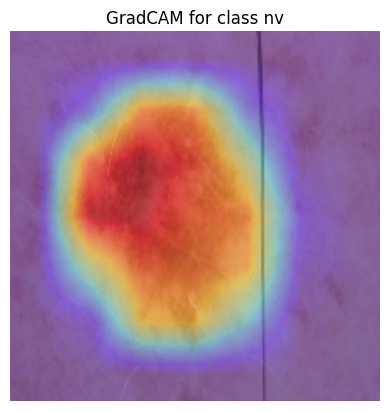

In [9]:


import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

def get_gradcam_heatmap(model, img_array, hand_features=None, pred_index=None, layer_name='convnext_tiny_stage_3_block_2_pointwise_conv_2'):
    """
    Generate GradCAM heatmap for a given image and prediction using specified layer_name
    """
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(layer_name).output, model.output]
    )

    inputs = [img_array]
    if hand_features is not None:
        inputs.append(hand_features)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(inputs)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]
    
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    
    # Normalize the heatmap
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()


def display_gradcam(img_path, model, class_names, top_n=3, layer_name='convnext_tiny_stage_3_block_2_pointwise_conv_2'):
    original_img = cv2.imread(img_path)
    original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    original_img_resized = cv2.resize(original_img, (IMG_SIZE, IMG_SIZE))
    
    img_array = convnext_preprocess(original_img_resized.astype(np.float32))
    img_array = np.expand_dims(img_array, axis=0)
    
    if USE_HANCRAFTED:
        hand_features = extract_handcrafted_features(img_path)
        hand_features = np.expand_dims(hand_features, axis=0)
        preds = model.predict([img_array, hand_features], verbose=0)
        heatmap = get_gradcam_heatmap(model, img_array, hand_features, pred_index=np.argmax(preds[0]), layer_name=layer_name)
    else:
        preds = model.predict(img_array, verbose=0)
        heatmap = get_gradcam_heatmap(model, img_array, pred_index=np.argmax(preds[0]), layer_name=layer_name)
    
    top_indices = np.argsort(preds[0])[::-1][:top_n]
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    fig.suptitle(f'GradCAM Visualization for {os.path.basename(img_path)}', fontsize=14)
    
    axes[0, 0].imshow(original_img_resized)
    axes[0, 0].set_title('Original Image')
    axes[0, 0].axis('off')
    
    pred_text = "Top Predictions:\n"
    for i, idx in enumerate(top_indices):
        pred_text += f"{i+1}. {class_names[idx]}: {preds[0][idx]*100:.2f}%\n"
    axes[0, 1].text(0.1, 0.5, pred_text, fontsize=12, verticalalignment='center')
    axes[0, 1].set_title('Model Predictions')
    axes[0, 1].axis('off')
    
    heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
    
    axes[1, 0].imshow(original_img_resized)
    axes[1, 0].imshow(heatmap_resized, cmap='jet', alpha=0.4)
    axes[1, 0].set_title(f'GradCAM - {class_names[top_indices[0]]}')
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(heatmap_resized, cmap='jet')
    axes[1, 1].set_title('Heatmap Only')
    axes[1, 1].axis('off')
    
    plt.tight_layout()
    plt.show()


# ================================================================
# استخدام GradCAM على صورة واحدة
# ================================================================
img_path = test_df['path'].iloc[0]
original_img = cv2.imread(img_path)
original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
original_img_resized = cv2.resize(original_img, (IMG_SIZE, IMG_SIZE))

img_array = convnext_preprocess(original_img_resized.astype(np.float32))
img_array = np.expand_dims(img_array, axis=0)
hand_features = extract_handcrafted_features(img_path)
hand_features = np.expand_dims(hand_features, axis=0)

preds = model.predict([img_array, hand_features])
heatmap = get_gradcam_heatmap(model, img_array, hand_features, pred_index=np.argmax(preds[0]), layer_name='convnext_tiny_stage_3_block_2_pointwise_conv_2')

plt.imshow(original_img_resized)
plt.imshow(cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE)), cmap='jet', alpha=0.4)
plt.title(f'GradCAM for class {le.classes_[np.argmax(preds[0])]}')
plt.axis('off')
plt.show()


 GradCAM Visualization - ConvNeXtTiny

 Displaying GradCAM on 20 images

 1. GradCAM Grid (Images with Heatmap Overlay):
----------------------------------------


/usr/local/lib/python3.13/dist-packages/skimage/feature/texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['image_input', 'hand_input']]
Received: inputs=['Tensor(shape=(1, 224, 224, 3))', 'Tensor(shape=(1, 58))']
  warnings.warn(msg)


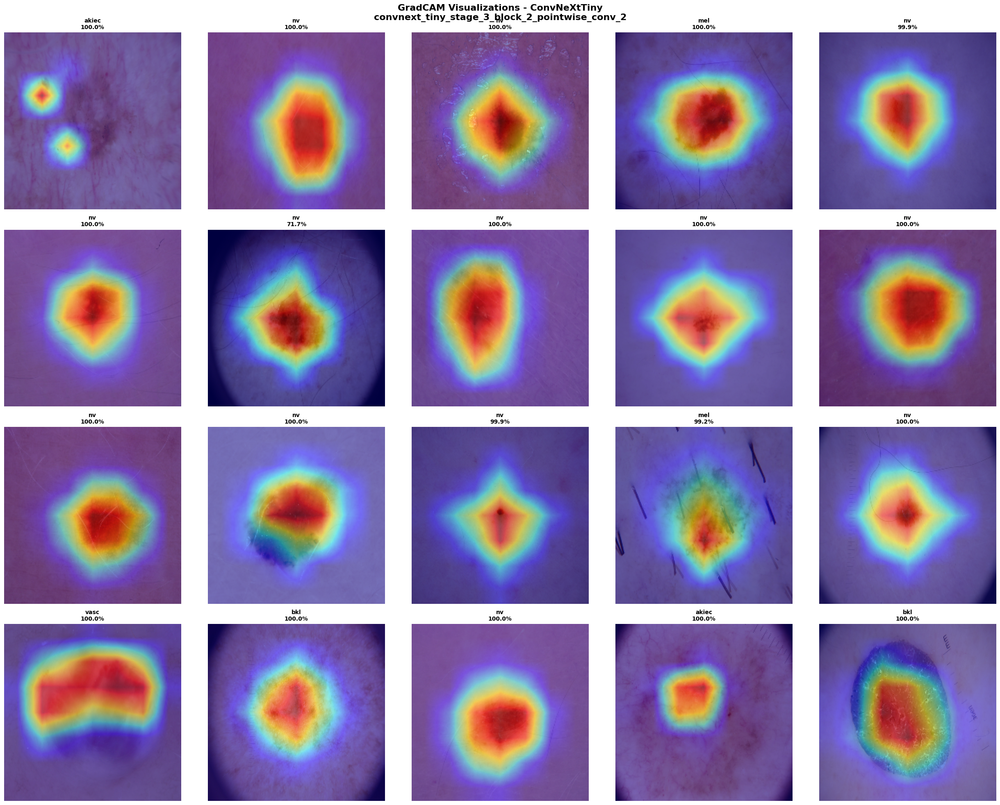


 GradCAM Results Summary
 1. ISIC_0028224.jpg                 → akiec        (100.0%)
 2. ISIC_0032401.jpg                 → nv           (100.0%)
 3. ISIC_0028030.jpg                 → nv           (100.0%)
 4. ISIC_0026360.jpg                 → mel          (100.0%)
 5. ISIC_0033078.jpg                 → nv           ( 99.9%)
 6. ISIC_0029817.jpg                 → nv           (100.0%)
 7. ISIC_0033611.jpg                 → nv           ( 71.7%)
 8. ISIC_0029707.jpg                 → nv           (100.0%)
 9. ISIC_0028849.jpg                 → nv           (100.0%)
10. ISIC_0029765.jpg                 → nv           (100.0%)
11. ISIC_0025459.jpg                 → nv           (100.0%)
12. ISIC_0032772.jpg                 → nv           (100.0%)
13. ISIC_0025073.jpg                 → nv           ( 99.9%)
14. ISIC_0025546.jpg                 → mel          ( 99.2%)
15. ISIC_0029845.jpg                 → nv           (100.0%)
16. ISIC_0032866.jpg                 → vasc         (100.0%

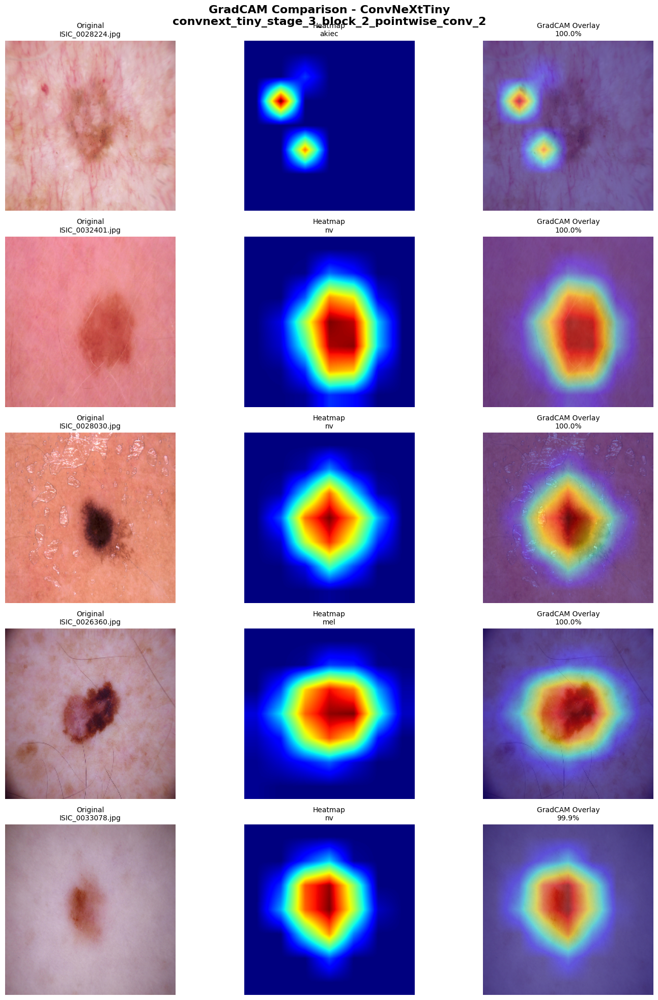


 GradCAM display completed!
 Number of images displayed: 20
 Layer used: convnext_tiny_stage_3_block_2_pointwise_conv_2


In [10]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
from sklearn.metrics import confusion_matrix
import seaborn as sns


# ================================================================
# Helper: Safe check for handcrafted features
# ================================================================
def _use_handcrafted():
    """تحقق آمن من تفعيل الـ handcrafted features."""
    return bool(globals().get('USE_HANCRAFTED', False))


# ================================================================
# GradCAM Heatmap
# ================================================================
def get_gradcam_heatmap(model, img_array, hand_features=None,
                        pred_index=None,
                        layer_name='convnext_tiny_stage_3_block_2_pointwise_conv_2'):
    """
    Generate GradCAM heatmap for a given image and prediction.
    Supports models with one or two inputs.
    """
    grad_model = None
    try:
        grad_model = tf.keras.models.Model(
            [model.inputs],
            [model.get_layer(layer_name).output, model.output]
        )
    except Exception:
        # ابحث عن طبقة بديلة
        for layer in reversed(model.layers):
            if 'conv' in layer.name and 'pointwise' in layer.name:
                grad_model = tf.keras.models.Model(
                    [model.inputs], [layer.output, model.output]
                )
                print(f" Using alternative layer: {layer.name}")
                break

    if grad_model is None:
        raise ValueError(f"Could not find layer '{layer_name}' or an alternative.")

    # بناء قائمة المدخلات
    inputs = [img_array]
    if hand_features is not None:
        inputs.append(hand_features)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(inputs)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # تطبيع
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()


# ================================================================
# Grid Display
# ================================================================
def display_gradcam_grid(images_paths, model, class_names,
                         grid_cols=5,
                         layer_name='convnext_tiny_stage_3_block_2_pointwise_conv_2'):
    """
    Display multiple GradCAM visualizations in a grid layout.
    """
    n_images = len(images_paths)
    grid_rows = (n_images + grid_cols - 1) // grid_cols

    fig_width  = grid_cols * 5
    fig_height = grid_rows * 5
    fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(fig_width, fig_height))
    fig.suptitle(f'GradCAM Visualizations - ConvNeXtTiny\n{layer_name}',
                 fontsize=16, fontweight='bold')

    if grid_rows == 1:
        axes = axes.reshape(1, -1)

    results = []
    use_hc = _use_handcrafted()   # ✅ الإصلاح

    for idx, img_path in enumerate(images_paths):
        row = idx // grid_cols
        col = idx % grid_cols
        ax = axes[row, col]

        try:
            # تحميل الصورة
            original_img = cv2.imread(img_path)
            if original_img is None:
                raise FileNotFoundError(f"Cannot read image: {img_path}")
            original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
            original_img_resized = cv2.resize(original_img, (IMG_SIZE, IMG_SIZE))

            img_array = convnext_preprocess(original_img_resized.astype(np.float32))
            img_array = np.expand_dims(img_array, axis=0)

            # التنبؤ
            if use_hc:   # ✅ الإصلاح
                hand_features = extract_handcrafted_features(img_path)
                hand_features = np.expand_dims(hand_features, axis=0)
                preds = model.predict([img_array, hand_features], verbose=0)
                heatmap = get_gradcam_heatmap(
                    model, img_array, hand_features,
                    pred_index=np.argmax(preds[0]),
                    layer_name=layer_name
                )
            else:
                preds = model.predict(img_array, verbose=0)
                heatmap = get_gradcam_heatmap(
                    model, img_array,
                    pred_index=np.argmax(preds[0]),
                    layer_name=layer_name
                )

            top_pred_idx = int(np.argmax(preds[0]))
            confidence   = float(np.max(preds[0]) * 100)
            pred_class   = class_names[top_pred_idx]

            heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))

            ax.imshow(original_img_resized)
            ax.imshow(heatmap_resized, cmap='jet', alpha=0.5)
            ax.set_title(f'{pred_class}\n{confidence:.1f}%',
                         fontsize=10, fontweight='bold')
            ax.axis('off')

            results.append({
                'path': img_path,
                'pred_class': pred_class,
                'confidence': confidence,
                'preds': preds[0],
                'heatmap': heatmap
            })

        except Exception as e:
            print(f" Error processing image {idx+1}: {e}")
            ax.text(0.5, 0.5, 'Error', ha='center', va='center')
            ax.axis('off')

    # إخفاء المربعات الفارغة
    for idx in range(len(images_paths), grid_rows * grid_cols):
        row = idx // grid_cols
        col = idx % grid_cols
        axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()
    return results


# ================================================================
# Grid + Summary
# ================================================================
def display_gradcam_grid_with_summary(images_paths, model, class_names,
                                      grid_cols=5,
                                      layer_name='convnext_tiny_stage_3_block_2_pointwise_conv_2'):
    """Display GradCAM grid + textual summary."""
    results = display_gradcam_grid(images_paths, model, class_names,
                                   grid_cols, layer_name)

    if results:
        print("\n" + "="*60)
        print(" GradCAM Results Summary")
        print("="*60)
        for i, r in enumerate(results):
            print(f"{i+1:2d}. {os.path.basename(r['path'])[:30]:<32} "
                  f"→ {r['pred_class']:<12} ({r['confidence']:>5.1f}%)")

        avg_confidence = np.mean([r['confidence'] for r in results])
        print(f"\n Average Confidence: {avg_confidence:.1f}%")

        class_counts = {}
        for r in results:
            class_counts[r['pred_class']] = class_counts.get(r['pred_class'], 0) + 1

        print("\n Class Distribution:")
        for class_name, count in sorted(class_counts.items()):
            print(f"  • {class_name}: {count} images")

    return results


# ================================================================
# Comparison Grid (Original / Heatmap / Overlay)
# ================================================================
def display_gradcam_comparison_grid(images_paths, model, class_names,
                                    layer_name='convnext_tiny_stage_3_block_2_pointwise_conv_2'):
    """Display GradCAM comparison between Original, Heatmap, and Overlay."""
    n_images = min(len(images_paths), 5)
    if n_images == 0:
        print("No images to display.")
        return

    fig, axes = plt.subplots(n_images, 3, figsize=(15, n_images * 4))
    fig.suptitle(f'GradCAM Comparison - ConvNeXtTiny\n{layer_name}',
                 fontsize=16, fontweight='bold')

    if n_images == 1:
        axes = axes.reshape(1, -1)

    use_hc = _use_handcrafted()   # ✅ الإصلاح

    for idx in range(n_images):
        img_path = images_paths[idx]
        try:
            original_img = cv2.imread(img_path)
            if original_img is None:
                raise FileNotFoundError(f"Cannot read image: {img_path}")
            original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
            original_img_resized = cv2.resize(original_img, (IMG_SIZE, IMG_SIZE))

            img_array = convnext_preprocess(original_img_resized.astype(np.float32))
            img_array = np.expand_dims(img_array, axis=0)

            if use_hc:   # ✅ الإصلاح
                hand_features = extract_handcrafted_features(img_path)
                hand_features = np.expand_dims(hand_features, axis=0)
                preds = model.predict([img_array, hand_features], verbose=0)
                heatmap = get_gradcam_heatmap(
                    model, img_array, hand_features,
                    pred_index=np.argmax(preds[0]),
                    layer_name=layer_name
                )
            else:
                preds = model.predict(img_array, verbose=0)
                heatmap = get_gradcam_heatmap(
                    model, img_array,
                    pred_index=np.argmax(preds[0]),
                    layer_name=layer_name
                )

            top_pred_idx = int(np.argmax(preds[0]))
            confidence   = float(np.max(preds[0]) * 100)
            pred_class   = class_names[top_pred_idx]

            heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))

            # العمود 1: الصورة الأصلية
            axes[idx, 0].imshow(original_img_resized)
            axes[idx, 0].set_title(f'Original\n{os.path.basename(img_path)[:20]}',
                                   fontsize=10)
            axes[idx, 0].axis('off')

            # العمود 2: الـ heatmap فقط
            axes[idx, 1].imshow(heatmap_resized, cmap='jet')
            axes[idx, 1].set_title(f'Heatmap\n{pred_class}', fontsize=10)
            axes[idx, 1].axis('off')

            # العمود 3: الصورة + الـ heatmap
            axes[idx, 2].imshow(original_img_resized)
            axes[idx, 2].imshow(heatmap_resized, cmap='jet', alpha=0.5)
            axes[idx, 2].set_title(f'GradCAM Overlay\n{confidence:.1f}%',
                                   fontsize=10)
            axes[idx, 2].axis('off')

        except Exception as e:
            print(f" Error in image {idx+1}: {e}")
            for col in range(3):
                axes[idx, col].text(0.5, 0.5, 'Error', ha='center', va='center')
                axes[idx, col].axis('off')

    plt.tight_layout()
    plt.show()


# ================================================================
# Main Execution
# ================================================================
print("\n" + "="*60)
print(" GradCAM Visualization - ConvNeXtTiny")
print("="*60)

GRADCAM_LAYER = 'convnext_tiny_stage_3_block_2_pointwise_conv_2'

NUM_IMAGES = 20
test_images = test_df['path'].sample(
    min(NUM_IMAGES, len(test_df)), random_state=44
).values

print(f"\n Displaying GradCAM on {len(test_images)} images")
print("="*60)

# 1. Grid + Summary
print("\n 1. GradCAM Grid (Images with Heatmap Overlay):")
print("-" * 40)
results = display_gradcam_grid_with_summary(
    images_paths=test_images,
    model=model,
    class_names=le.classes_,
    grid_cols=5,
    layer_name=GRADCAM_LAYER
)

# 2. Comparison
print("\n 2. GradCAM Comparison (Original vs Heatmap vs Overlay):")
print("-" * 40)
display_gradcam_comparison_grid(
    images_paths=test_images[:5],
    model=model,
    class_names=le.classes_,
    layer_name=GRADCAM_LAYER
)

print("\n" + "="*60)
print(" GradCAM display completed!")
print(f" Number of images displayed: {len(test_images)}")
print(f" Layer used: {GRADCAM_LAYER}")
print("="*60)

In [11]:


# Model Architecture Visualization
# ================================================================
def visualize_model_architecture():
    """
    Create a summary visualization of the model architecture
    """
    print("\n" + "="*50)
    print("Model Architecture Summary")
    print("="*50)
    
    # Count parameters
    total_params = model.count_params()
    trainable_params = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
    non_trainable_params = total_params - trainable_params
    
    print(f"Total Parameters: {total_params:,}")
    print(f"Trainable Parameters: {trainable_params:,}")
    print(f"Non-trainable Parameters: {non_trainable_params:,}")
    # Model summary
    print(f"\nModel Type: EfficientNetB6 + Custom Head")
    print(f"Input Image Size: {IMG_SIZE}x{IMG_SIZE}x3")
   # if USE_HANCRAFTED:
   #     print(f"Handcrafted Features: {handcraft_dim} dimensions")
   # print(f"Output Classes: {num_classes}")
   # print(f"Base Model: {'Fine-tuned' if base_model.layers[0].trainable else 'Frozen'}")
    
    # Layer information
    conv_layers = sum(1 for layer in model.layers if 'conv' in layer.name.lower())
    dense_layers = sum(1 for layer in model.layers if 'dense' in layer.name.lower())
    dropout_layers = sum(1 for layer in model.layers if 'dropout' in layer.name.lower())
    
    print(f"\nLayer Composition:")
    print(f"- Convolutional layers: {conv_layers}")
    print(f"- Dense layers: {dense_layers}")
    print(f"- Dropout layers: {dropout_layers}")

# Call the architecture visualization
visualize_model_architecture()


Model Architecture Summary
Total Parameters: 28,042,255
Trainable Parameters: 28,040,603
Non-trainable Parameters: 1,652

Model Type: EfficientNetB6 + Custom Head
Input Image Size: 224x224x3

Layer Composition:
- Convolutional layers: 131
- Dense layers: 3
- Dropout layers: 2


In [12]:
# ================================================================
# Model Architecture Visualization - ConvNeXtTiny (نسخة محسنة)
# ================================================================
def visualize_model_architecture():
    """
    Create a comprehensive visualization of the model architecture
    """
    print("\n" + "="*60)
    print(" Model Architecture Summary - ConvNeXtTiny")
    print("="*60)
    
    # Count parameters
    total_params = model.count_params()
    trainable_params = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
    non_trainable_params = total_params - trainable_params
    
    print(f"\n Parameter Statistics:")
    print("-" * 50)
    print(f"  • Total Parameters: {total_params:,}")
    print(f"  • Trainable Parameters: {trainable_params:,} ({trainable_params/total_params*100:.1f}%)")
    print(f"  • Non-trainable Parameters: {non_trainable_params:,} ({non_trainable_params/total_params*100:.1f}%)")
    
    # Model type and configuration
    print(f"\n Model Configuration:")
    print("-" * 50)
    print(f"  • Model Type: ConvNeXtTiny")
    print(f"  • Input Image Size: {IMG_SIZE}x{IMG_SIZE}x3")
    if USE_HANCRAFTED:
        print(f"  • Handcrafted Features: {handcraft_dim} dimensions")
        print(f"  • Input Mode: Dual Input (Image + Handcrafted)")
    else:
        print(f"  • Input Mode: Single Input (Image only)")
    print(f"  • Output Classes: {num_classes}")
    print(f"  • Training Mode: {'Fine-tuned (All layers trainable)' if base_model.layers[0].trainable else 'Frozen'}")
    
    # Base Model Architecture (ConvNeXtTiny)
    print(f"\n ConvNeXtTiny Architecture:")
    print("-" * 50)
    
    # Get ConvNeXt stages information
    convnext_layers = [layer for layer in model.layers if 'convnext_tiny_stage' in layer.name]
    stages = {}
    for layer in convnext_layers:
        if '_stage_' in layer.name:
            try:
                stage_num = layer.name.split('_stage_')[1].split('_')[0]
                if stage_num not in stages:
                    stages[stage_num] = {'count': 0, 'params': 0}
                stages[stage_num]['count'] += 1
                try:
                    stages[stage_num]['params'] += layer.count_params()
                except:
                    pass
            except:
                pass
    
    if stages:
        stage_names = ['Stem', 'Stage 0', 'Stage 1', 'Stage 2', 'Stage 3']
        for stage in sorted(stages.keys()):
            name = stage_names[int(stage)] if int(stage) < len(stage_names) else f'Stage {stage}'
            print(f"  • {name}: {stages[stage]['count']} layers, {stages[stage]['params']:,} parameters")
    
    # Count different layer types in the base model
    base_layers = base_model.layers
    layer_types = {}
    for layer in base_layers:
        layer_class = layer.__class__.__name__
        if layer_class not in layer_types:
            layer_types[layer_class] = 0
        layer_types[layer_class] += 1
    
    print(f"\n Base Model Layer Composition:")
    print("-" * 50)
    for layer_type, count in sorted(layer_types.items(), key=lambda x: x[1], reverse=True)[:10]:
        print(f"  • {layer_type}: {count}")
    if len(layer_types) > 10:
        print(f"  • ... and {len(layer_types) - 10} more types")
    
    # Custom Head Architecture
    print(f"\n Custom Head Architecture:")
    print("-" * 50)
    
    # Find the custom head layers (after base model)
    head_layers = []
    base_layer_names = [l.name for l in base_model.layers]
    for layer in model.layers:
        if layer.name not in base_layer_names:
            head_layers.append(layer)
    
    for layer in head_layers:
        if layer.__class__.__name__ in ['InputLayer', 'Input']:
            continue
        layer_type = layer.__class__.__name__
        if hasattr(layer, 'units'):
            print(f"  • {layer.name}: {layer_type} (units={layer.units})")
        elif hasattr(layer, 'rate'):
            print(f"  • {layer.name}: {layer_type} (rate={layer.rate})")
        else:
            print(f"  • {layer.name}: {layer_type}")
    
    # Custom Head Layers Summary (المفيد فقط)
    print(f"\n Custom Head Layers Summary:")
    print("-" * 80)
    print(f"{'Layer Name':<35} {'Type':<20} {'Output Shape':<25}")
    print("-" * 80)
    
    for layer in head_layers:
        if layer.__class__.__name__ in ['InputLayer', 'Input']:
            continue
        layer_type = layer.__class__.__name__
        try:
            if hasattr(layer, 'output_shape'):
                output_shape = str(layer.output_shape)
            else:
                output_shape = "N/A"
        except:
            output_shape = "N/A"
        print(f"{layer.name[:32]:<35} {layer_type[:18]:<20} {str(output_shape)[:24]:<25}")
    
    # Input and output details
    print(f"\n Input Details:")
    print("-" * 50)
    for i, input_layer in enumerate(model.inputs):
        print(f"  • Input {i+1}: {input_layer.name} - shape: {input_layer.shape}")
    
    print(f"\n Output Details:")
    print("-" * 50)
    for i, output_layer in enumerate(model.outputs):
        print(f"  • Output {i+1}: {output_layer.name} - shape: {output_layer.shape}")
    
    # Total layers count
    print(f"\n Total Layers: {len(model.layers)}")
    
    # Memory usage estimate (approximate)
    memory_mb = total_params * 4 / (1024 * 1024)
    print(f" Estimated Memory Usage: {memory_mb:.1f} MB (float32)")
    
    print("\n" + "="*60)
    print(" Model Architecture Visualization Complete!")
    print("="*60)


# ================================================================
# Model Complexity Analysis
# ================================================================
def analyze_model_complexity():
    """
    Analyze model complexity in terms of FLOPs and layer distribution
    """
    print("\n" + "="*60)
    print(" Model Complexity Analysis - ConvNeXtTiny")
    print("="*60)
    
    # Count layers by type
    layer_counts = {}
    trainable_counts = {}
    param_counts = {}
    
    for layer in model.layers:
        layer_type = layer.__class__.__name__
        if layer_type not in layer_counts:
            layer_counts[layer_type] = 0
            trainable_counts[layer_type] = 0
            param_counts[layer_type] = 0
        
        layer_counts[layer_type] += 1
        if layer.trainable:
            trainable_counts[layer_type] += 1
        try:
            param_counts[layer_type] += layer.count_params()
        except:
            pass
    
    print(f"\n Layer Distribution:")
    print("-" * 60)
    print(f"{'Layer Type':<25} {'Count':<10} {'Trainable':<12} {'Parameters':<15}")
    print("-" * 60)
    
    for layer_type in sorted(layer_counts.keys(), key=lambda x: param_counts[x], reverse=True):
        print(f"{layer_type[:23]:<25} {layer_counts[layer_type]:<10} {trainable_counts[layer_type]:<12} {param_counts[layer_type]:>12,}")
    
    # ConvNeXt specific analysis
    print(f"\n ConvNeXt Stage Breakdown:")
    print("-" * 60)
    
    stage_info = {}
    for layer in model.layers:
        if 'convnext_tiny_stage' in layer.name:
            try:
                stage_num = layer.name.split('_stage_')[1].split('_')[0]
                if stage_num not in stage_info:
                    stage_info[stage_num] = {'layers': 0, 'params': 0}
                stage_info[stage_num]['layers'] += 1
                try:
                    stage_info[stage_num]['params'] += layer.count_params()
                except:
                    pass
            except:
                pass
    
    stage_names = ['Input Stem', 'Stage 0', 'Stage 1', 'Stage 2', 'Stage 3']
    for stage in sorted(stage_info.keys()):
        info = stage_info[stage]
        name = stage_names[int(stage) + 1] if int(stage) + 1 < len(stage_names) else f'Stage {stage}'
        print(f"  • {name}: {info['layers']} layers, {info['params']:,} parameters")
    
    # Calculate model size
    print(f"\n Model Size Breakdown:")
    print("-" * 60)
    
    # Base model vs custom head
    base_params = sum([layer.count_params() for layer in base_model.layers if hasattr(layer, 'count_params')])
    total_params = model.count_params()
    custom_params = total_params - base_params
    
    print(f"  • Base Model (ConvNeXtTiny): {base_params:,} parameters ({base_params/total_params*100:.1f}%)")
    print(f"  • Custom Head: {custom_params:,} parameters ({custom_params/total_params*100:.1f}%)")
    
    # Memory analysis
    memory_mb = total_params * 4 / (1024 * 1024)
    print(f"\n Memory Requirements:")
    print(f"  • Model Weights: {memory_mb:.1f} MB (float32)")
    print(f"  • Input Image: {IMG_SIZE*IMG_SIZE*3*4 / (1024*1024):.2f} MB per image")
    print(f"  • Batch Memory: {BATCH_SIZE * IMG_SIZE*IMG_SIZE*3*4 / (1024*1024):.2f} MB per batch")
    
    print("\n" + "="*60)


# ================================================================
# Execute Visualizations
# ================================================================
visualize_model_architecture()
analyze_model_complexity()
# visualize_layer_shapes()


 Model Architecture Summary - ConvNeXtTiny

 Parameter Statistics:
--------------------------------------------------
  • Total Parameters: 28,042,255
  • Trainable Parameters: 28,040,603 (100.0%)
  • Non-trainable Parameters: 1,652 (0.0%)

 Model Configuration:
--------------------------------------------------
  • Model Type: ConvNeXtTiny
  • Input Image Size: 224x224x3
  • Handcrafted Features: 58 dimensions
  • Input Mode: Dual Input (Image + Handcrafted)
  • Output Classes: 7
  • Training Mode: Fine-tuned (All layers trainable)

 ConvNeXtTiny Architecture:
--------------------------------------------------
  • Stem: 21 layers, 237,888 parameters
  • Stage 0: 21 layers, 918,144 parameters
  • Stage 1: 63 layers, 10,817,280 parameters
  • Stage 2: 21 layers, 14,289,408 parameters

 Base Model Layer Composition:
--------------------------------------------------
  • Dense: 36
  • Activation: 36
  • LayerNormalization: 19
  • Conv2D: 18
  • LayerScale: 18
  • Sequential: 4
  • InputL


Data Augmentation Visualization


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


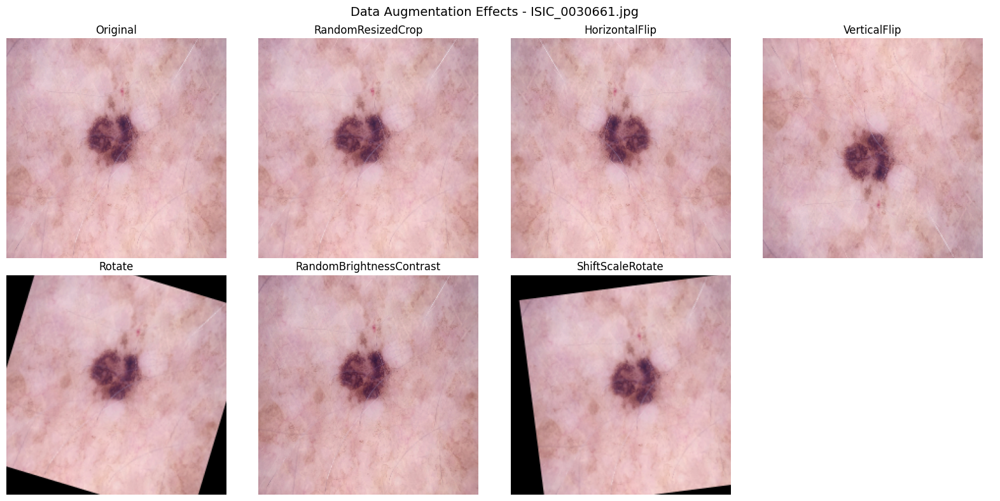

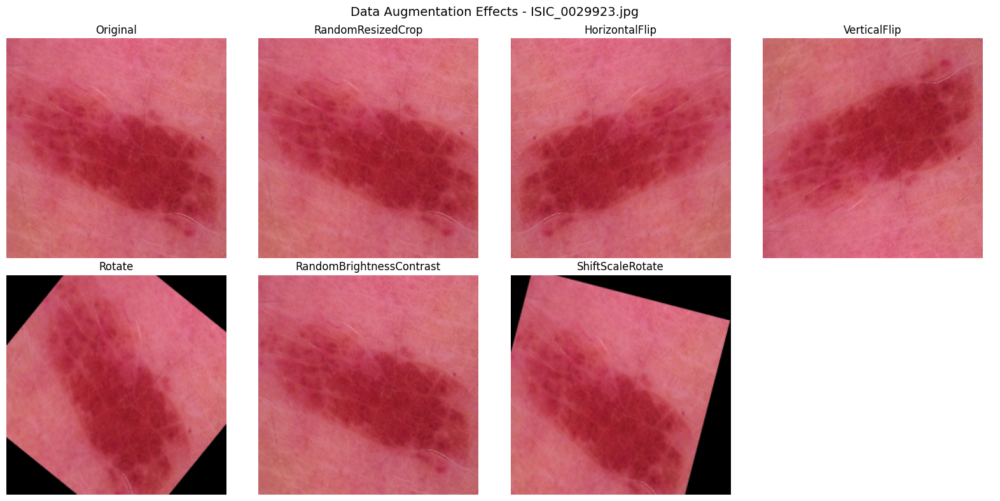

In [13]:
# NEW FEATURE 2: Data Augmentation Visualization
# ================================================================
def visualize_augmentations(img_path, num_samples=1):
    """
    Visualize different augmentation effects on an image
    """
    # Load original image
    original_img = cv2.imread(img_path)
    original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    
    # Define individual augmentations
    augmentations = {
        'Original': A.Compose([A.Resize(IMG_SIZE, IMG_SIZE)]),
        'RandomResizedCrop': A.Compose([A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.8, 1.0), p=1.0)]),
        'HorizontalFlip': A.Compose([A.Resize(IMG_SIZE, IMG_SIZE), A.HorizontalFlip(p=1.0)]),
        'VerticalFlip': A.Compose([A.Resize(IMG_SIZE, IMG_SIZE), A.VerticalFlip(p=1.0)]),
        'Rotate': A.Compose([A.Resize(IMG_SIZE, IMG_SIZE), A.Rotate(limit=45, p=1.0)]),
        'RandomBrightnessContrast': A.Compose([A.Resize(IMG_SIZE, IMG_SIZE), A.RandomBrightnessContrast(p=1.0)]),
        'ShiftScaleRotate': A.Compose([A.Resize(IMG_SIZE, IMG_SIZE), A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=1.0)])
    }
    # Create subplots
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle(f'Data Augmentation Effects - {os.path.basename(img_path)}', fontsize=14)
    
    axes = axes.flatten()
    
    for i, (aug_name, transform) in enumerate(augmentations.items()):
        # Apply augmentation
        augmented = transform(image=original_img)["image"]
        
        # Display
        axes[i].imshow(augmented)
        axes[i].set_title(aug_name)
        axes[i].axis('off')
    
    # Remove empty subplot
    if len(augmentations) < 8:
        axes[7].axis('off')
    
    plt.tight_layout()
    plt.show()

# Select 2 random images for augmentation visualization
print("\n" + "="*50)
print("Data Augmentation Visualization")
print("="*50)

aug_images = train_df['path'].sample(2, random_state=42).values
for img_path in aug_images:
    visualize_augmentations(img_path)


In [14]:
# ================================================================
# NEW FEATURE 3: LBP Feature Visualization
# ================================================================
# For handcrafted features
from skimage.feature import local_binary_pattern
from skimage.color import rgb2gray

# For GradCAM
from tensorflow.keras.models import Model
import matplotlib.cm as cm
def visualize_lbp_features(img_path):
    """
    Visualize LBP (Local Binary Pattern) feature extraction
    """
    # Load original image
    original_img = cv2.imread(img_path)
    original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    
    # Resize for processing
    img_resized = cv2.resize(original_img, (128, 128))
    
    # Convert to grayscale
    gray_img = rgb2gray(img_resized)
    
    # Compute LBP with different parameters
    lbp_uniform = local_binary_pattern(gray_img, P=8, R=1, method='uniform')
    lbp_default = local_binary_pattern(gray_img, P=8, R=1, method='default')
    lbp_ror = local_binary_pattern(gray_img, P=8, R=1, method='ror')
     # Compute histograms
    n_bins_uniform = int(lbp_uniform.max() + 1)
    hist_uniform, _ = np.histogram(lbp_uniform, bins=n_bins_uniform, range=(0, n_bins_uniform), density=True)
    
    # Create subplots
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(f'LBP Feature Extraction - {os.path.basename(img_path)}', fontsize=14)
    
    # Original image
    axes[0, 0].imshow(original_img)
    axes[0, 0].set_title('Original Image')
    axes[0, 0].axis('off')
    
    # Grayscale image
    axes[0, 1].imshow(gray_img, cmap='gray')
    axes[0, 1].set_title('Grayscale')
    axes[0, 1].axis('off')
    
    # LBP Uniform
    axes[0, 2].imshow(lbp_uniform, cmap='gray')
    axes[0, 2].set_title('LBP Uniform')
    axes[0, 2].axis('off')
    # LBP Default
   # axes[1, 0].imshow(lbp_default, cmap='gray')
   # axes[1, 0].set_title('LBP Default')
   # axes[1, 0].axis('off')
    
    # LBP ROR
   # axes[1, 1].imshow(lbp_ror, cmap='gray')
   # axes[1, 1].set_title('LBP ROR')
   # axes[1, 1].axis('off')
    
    # Histogram
    axes[1, 2].bar(range(len(hist_uniform)), hist_uniform)
    axes[1, 2].set_title('LBP Uniform Histogram')
    axes[1, 2].set_xlabel('LBP Value')
    axes[1, 2].set_ylabel('Frequency')
    
    plt.tight_layout()
    plt.show()
    
    return hist_uniform

# Select 3 random images for LBP visualization
print("\n" + "="*50)
print("LBP Feature Extraction Visualization")
print("="*50)


LBP Feature Extraction Visualization


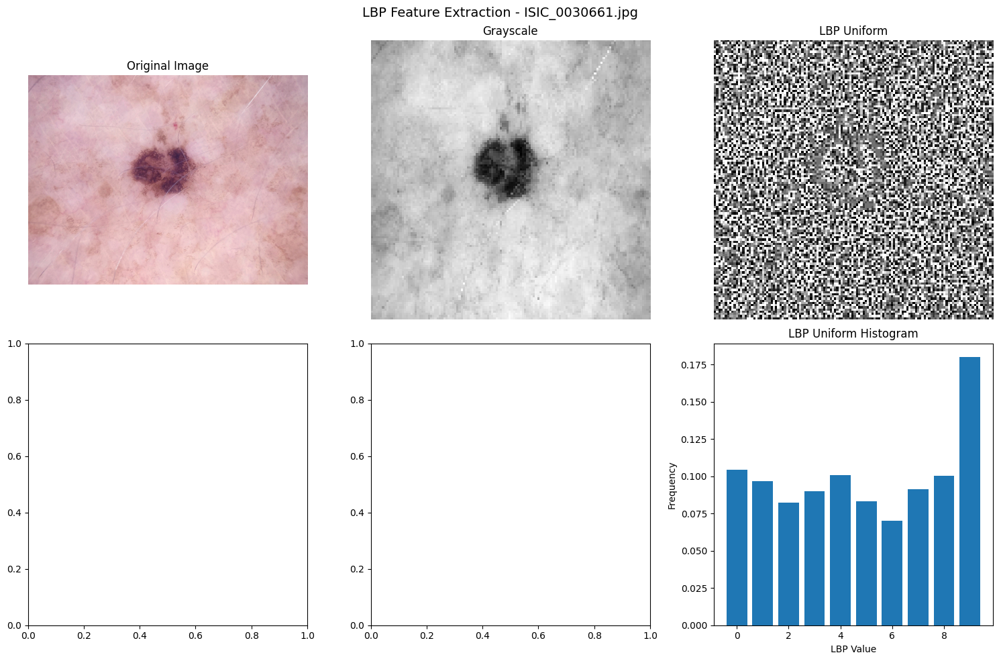

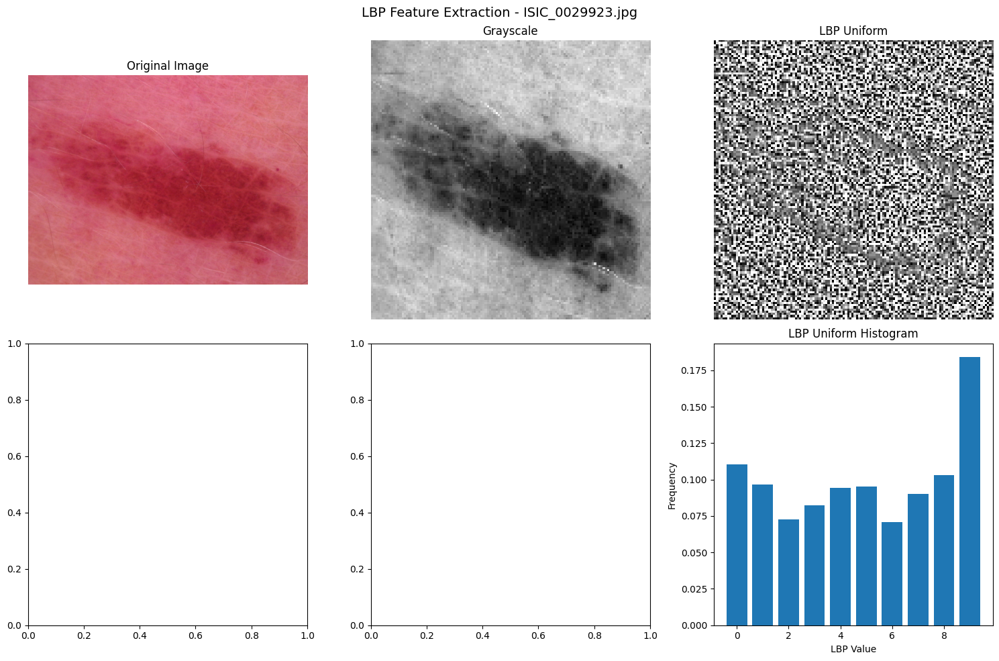

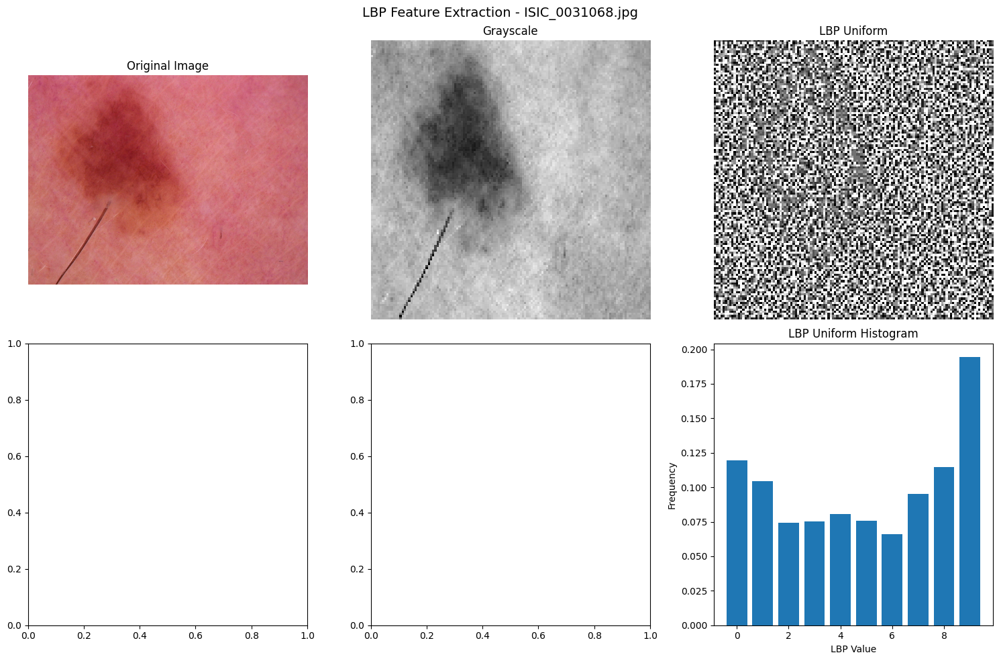

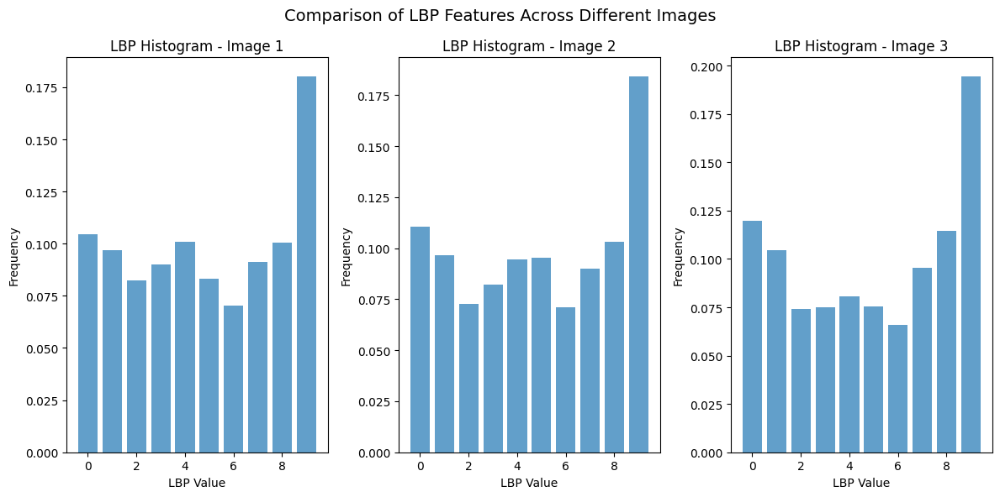

In [15]:
lbp_images = train_df['path'].sample(3, random_state=42).values
lbp_features = []
for img_path in lbp_images:
    hist = visualize_lbp_features(img_path)
    lbp_features.append(hist)
# Compare LBP features across different images
plt.figure(figsize=(12, 6))
for i, (img_path, hist) in enumerate(zip(lbp_images, lbp_features)):
    plt.subplot(1, 3, i+1)
    plt.bar(range(len(hist)), hist, alpha=0.7, label=f'Image {i+1}')
    plt.title(f'LBP Histogram - Image {i+1}')
    plt.xlabel('LBP Value')
    plt.ylabel('Frequency')

plt.suptitle('Comparison of LBP Features Across Different Images', fontsize=14)
plt.tight_layout()
plt.show()



 Displaying GradCAM on 20 images from Test Data

 GradCAM Grid (Images with Heatmap Overlay):
----------------------------------------
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_pointwise_conv_2
 Using alternative layer: convnext_tiny_stage_3_block_2_poin

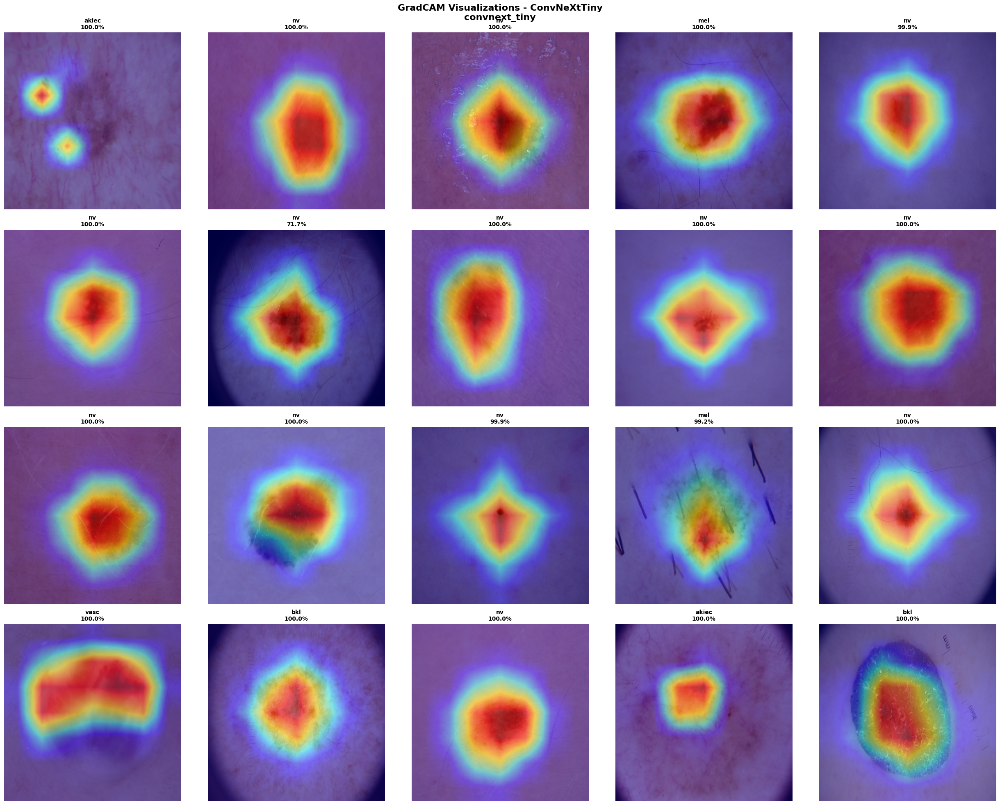


 GradCAM Results Summary
 1. ISIC_0028224.jpg                 → akiec        (100.0%)
 2. ISIC_0032401.jpg                 → nv           (100.0%)
 3. ISIC_0028030.jpg                 → nv           (100.0%)
 4. ISIC_0026360.jpg                 → mel          (100.0%)
 5. ISIC_0033078.jpg                 → nv           ( 99.9%)
 6. ISIC_0029817.jpg                 → nv           (100.0%)
 7. ISIC_0033611.jpg                 → nv           ( 71.7%)
 8. ISIC_0029707.jpg                 → nv           (100.0%)
 9. ISIC_0028849.jpg                 → nv           (100.0%)
10. ISIC_0029765.jpg                 → nv           (100.0%)
11. ISIC_0025459.jpg                 → nv           (100.0%)
12. ISIC_0032772.jpg                 → nv           (100.0%)
13. ISIC_0025073.jpg                 → nv           ( 99.9%)
14. ISIC_0025546.jpg                 → mel          ( 99.2%)
15. ISIC_0029845.jpg                 → nv           (100.0%)
16. ISIC_0032866.jpg                 → vasc         (100.0%

In [16]:
# ================================================================
# Display GradCAM on 30 images from test data
# ================================================================
print("\n" + "="*60)
#print(" GradCAM Visualization - ConvNeXtTiny (30 Images from Test Data)")
print("="*60)

# Select 50 random images from test dataconvnext_tiny_stage_3_block_2_pointwise_conv_2
NUM_IMAGES = 20
test_images = test_df['path'].sample(min(NUM_IMAGES, len(test_df)), random_state=44).values

print(f"\n Displaying GradCAM on {len(test_images)} images from Test Data")
print("="*60)

# Display main grid
print("\n GradCAM Grid (Images with Heatmap Overlay):")
print("-" * 40)
results = display_gradcam_grid_with_summary(
    images_paths=test_images,
    model=model,
    class_names=le.classes_,
    grid_cols=5,  # 5 columns
    layer_name='convnext_tiny'
    # Removed dataset_name
)

print("\n" + "="*60)
print(f" GradCAM display completed on {len(test_images)} images!")
print("="*60)

In [17]:
1

1

In [18]:
model.save('1-convnext_best.keras')


#model.save_weights('2-convnext_best_weights.h5')


model.export('saved_model/')

INFO:tensorflow:Assets written to: saved_model/assets


INFO:tensorflow:Assets written to: saved_model/assets


Saved artifact at 'saved_model/'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image_input'), TensorSpec(shape=(None, 58), dtype=tf.float32, name='hand_input')]
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  137138632769808: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  137138632769616: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  137146780660944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137138632772496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137138632771536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137138632772112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137138632772880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137138632773840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137138632772688: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [19]:
import tensorflow as tf

def detailed_model_summary(model):
    print("=" * 80)
    print("MODEL SUMMARY")
    print("=" * 80)
    model.summary()
    
    print("\n" + "=" * 80)
    print("LAYER DETAILS")
    print("=" * 80)
    for i, layer in enumerate(model.layers):
        print(f"\nLayer {i}: {layer.name}")
        print(f"  Type: {layer.__class__.__name__}")
        
        # Handle InputLayer separately with safe checks
        if isinstance(layer, tf.keras.layers.InputLayer):
            # Safely get input shape
            if hasattr(layer, 'input_spec') and layer.input_spec is not None:
                if hasattr(layer.input_spec, 'shape'):
                    print(f"  Input shape: {layer.input_spec.shape}")
                else:
                    print(f"  Input shape: {layer.input_spec}")
            elif hasattr(layer, 'batch_input_shape'):
                print(f"  Input shape: {layer.batch_input_shape}")
            elif hasattr(layer, 'input_shape'):
                print(f"  Input shape: {layer.input_shape}")
            else:
                print(f"  Input shape: N/A")
            
            # InputLayer typically doesn't have output shape, but we can try
            if hasattr(layer, 'output_shape'):
                print(f"  Output shape: {layer.output_shape}")
            else:
                print(f"  Output shape: Same as input")
        else:
            # For other layers, safely get input and output shapes
            try:
                if hasattr(layer, 'input_shape') and layer.input_shape is not None:
                    print(f"  Input shape: {layer.input_shape}")
                elif hasattr(layer, 'input') and layer.input is not None:
                    if hasattr(layer.input, 'shape'):
                        print(f"  Input shape: {layer.input.shape}")
                    else:
                        print(f"  Input shape: N/A")
                else:
                    print(f"  Input shape: N/A")
            except Exception as e:
                print(f"  Input shape: N/A ({str(e)})")
            
            try:
                if hasattr(layer, 'output_shape') and layer.output_shape is not None:
                    print(f"  Output shape: {layer.output_shape}")
                elif hasattr(layer, 'output') and layer.output is not None:
                    if hasattr(layer.output, 'shape'):
                        print(f"  Output shape: {layer.output.shape}")
                    else:
                        print(f"  Output shape: N/A")
                else:
                    print(f"  Output shape: N/A")
            except Exception as e:
                print(f"  Output shape: N/A ({str(e)})")
        
        # Print common attributes safely
        if hasattr(layer, 'trainable'):
            print(f"  Trainable: {layer.trainable}")
        if hasattr(layer, 'units'):
            print(f"  Units: {layer.units}")
        if hasattr(layer, 'activation') and layer.activation is not None:
            if hasattr(layer.activation, '__name__'):
                print(f"  Activation: {layer.activation.__name__}")
            else:
                print(f"  Activation: {layer.activation}")
        if hasattr(layer, 'filters'):
            print(f"  Filters: {layer.filters}")
        if hasattr(layer, 'kernel_size'):
            print(f"  Kernel size: {layer.kernel_size}")
        if hasattr(layer, 'pool_size'):
            print(f"  Pool size: {layer.pool_size}")
        if hasattr(layer, 'strides'):
            print(f"  Strides: {layer.strides}")
        if hasattr(layer, 'padding'):
            print(f"  Padding: {layer.padding}")
        if hasattr(layer, 'dropout'):
            print(f"  Dropout: {layer.dropout}")
        if hasattr(layer, 'rate'):
            print(f"  Rate: {layer.rate}")

# Call the function
detailed_model_summary(model)

MODEL SUMMARY


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_pres… │ (None, 224, 224,  │          0 │ image_input[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stem  │ (None, 56, 56,    │      4,896 │ convnext_tiny_pr… │
│ (Sequential)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ convnext_tiny_st… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st… │
│ (LayerScale)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│                     │ 96)               │            │ convnext_tiny_st… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ add[0][0]         │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st

 Total params: 84,123,463 (320.91 MB)

 Trainable params: 28,040,603 (106.97 MB)

 Non-trainable params: 1,652 (6.45 KB)

 Optimizer params: 56,081,208 (213.93 MB)


LAYER DETAILS

Layer 0: image_input
  Type: InputLayer
  Input shape: N/A
  Output shape: Same as input
  Trainable: True

Layer 1: convnext_tiny_prestem_normalization
  Type: Normalization
  Input shape: (None, 224, 224, 3)
  Output shape: (None, 224, 224, 3)
  Trainable: True

Layer 2: convnext_tiny_stem
  Type: Sequential
  Input shape: (None, 224, 224, 3)
  Output shape: (None, 56, 56, 96)
  Trainable: True

Layer 3: convnext_tiny_stage_0_block_0_depthwise_conv
  Type: Conv2D
  Input shape: (None, 56, 56, 96)
  Output shape: (None, 56, 56, 96)
  Trainable: True
  Activation: linear
  Filters: 96
  Kernel size: (7, 7)
  Strides: (1, 1)
  Padding: same

Layer 4: convnext_tiny_stage_0_block_0_layernorm
  Type: LayerNormalization
  Input shape: (None, 56, 56, 96)
  Output shape: (None, 56, 56, 96)
  Trainable: True

Layer 5: convnext_tiny_stage_0_block_0_pointwise_conv_1
  Type: Dense
  Input shape: (None, 56, 56, 96)
  Output shape: (None, 56, 56, 384)
  Trainable: True
  Units: 384


Listing images: 100%|██████████| 10015/10015 [00:00<00:00, 17637.67it/s]


Total images found: 10015
Label distribution:
 label
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Train: 7009  Val: 1503  Test: 1503

Building ConvNeXtTiny feature extractor...
Feature extractor output shape: (None, 768)


Test CNN feats: 100%|██████████| 24/24 [00:21<00:00,  1.09it/s]


CNN features shape: (7009, 768)


Train handcrafted:   0%|          | 0/7009 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/skimage/feature/texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(
Test handcrafted: 100%|██████████| 1503/1503 [00:18<00:00, 81.60it/s]


Final feature vector shape: (7009, 826)

############################################################
🔹 Training: SVM
############################################################
Val Accuracy : 0.8337
Test Accuracy: 0.8184

 COMPLETE METRICS SUMMARY - SVM
 Accuracy    : 81.84%
 Specificity : 95.06%
 Precision   : 72.84%
 Sensitivity : 57.53%
 F1 Score    : 61.76%

Per-class Specificity:
  akiec : 98.56%
  bcc   : 98.11%
  bkl   : 95.59%
  df    : 99.93%
  mel   : 96.26%
  nv    : 77.06%
  vasc  : 99.93%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.5800    0.5918    0.5859        49
         bcc     0.6582    0.6753    0.6667        77
         bkl     0.6467    0.6545    0.6506       165
          df     0.8000    0.2353    0.3636        17
         mel     0.6124    0.4731    0.5338       167
          nv     0.8927    0.9423    0.9168      1006
        vasc     0.9091    0.4545    0.6061        22

    accuracy              

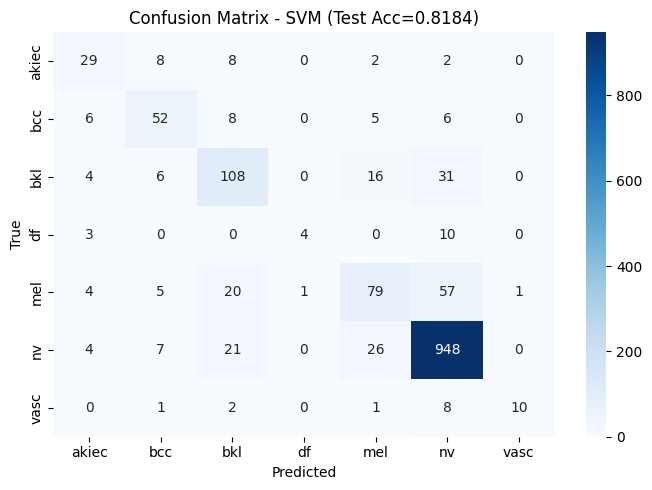


############################################################
🔹 Training: RandomForest
############################################################
Val Accuracy : 0.7006
Test Accuracy: 0.7013

 COMPLETE METRICS SUMMARY - RandomForest
 Accuracy    : 70.13%
 Specificity : 87.40%
 Precision   : 54.44%
 Sensitivity : 21.38%
 F1 Score    : 23.80%

Per-class Specificity:
  akiec : 99.79%
  bcc   : 99.93%
  bkl   : 99.70%
  df    : 100.00%
  mel   : 99.33%
  nv    : 13.08%
  vasc  : 100.00%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.7692    0.2041    0.3226        49
         bcc     0.8750    0.0909    0.1647        77
         bkl     0.7778    0.0848    0.1530       165
          df     0.0000    0.0000    0.0000        17
         mel     0.6897    0.1198    0.2041       167
          nv     0.6990    0.9970    0.8218      1006
        vasc     0.0000    0.0000    0.0000        22

    accuracy                         0.7013   

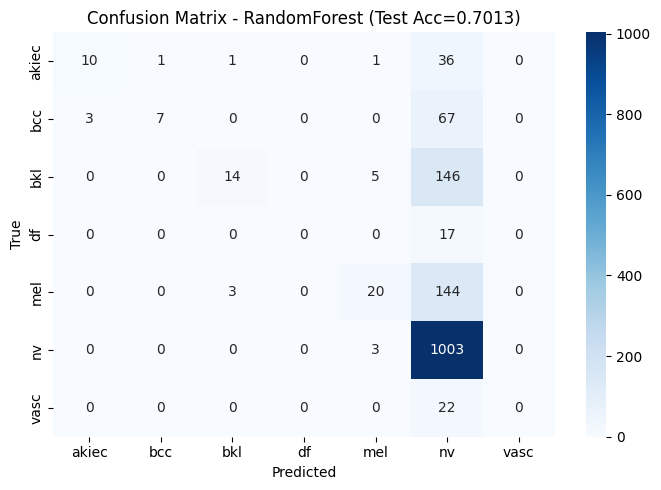


############################################################
🔹 Training: LogReg
############################################################
Val Accuracy : 0.7611
Test Accuracy: 0.7352

 COMPLETE METRICS SUMMARY - LogReg
 Accuracy    : 73.52%
 Specificity : 94.44%
 Precision   : 54.64%
 Sensitivity : 57.09%
 F1 Score    : 55.40%

Per-class Specificity:
  akiec : 97.18%
  bcc   : 96.91%
  bkl   : 93.20%
  df    : 99.39%
  mel   : 90.27%
  nv    : 84.51%
  vasc  : 99.59%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.3594    0.4694    0.4071        49
         bcc     0.5111    0.5974    0.5509        77
         bkl     0.5211    0.6000    0.5577       165
          df     0.4375    0.4118    0.4242        17
         mel     0.4144    0.5509    0.4730       167
          nv     0.9147    0.8211    0.8654      1006
        vasc     0.6667    0.5455    0.6000        22

    accuracy                         0.7352      1503
   mac

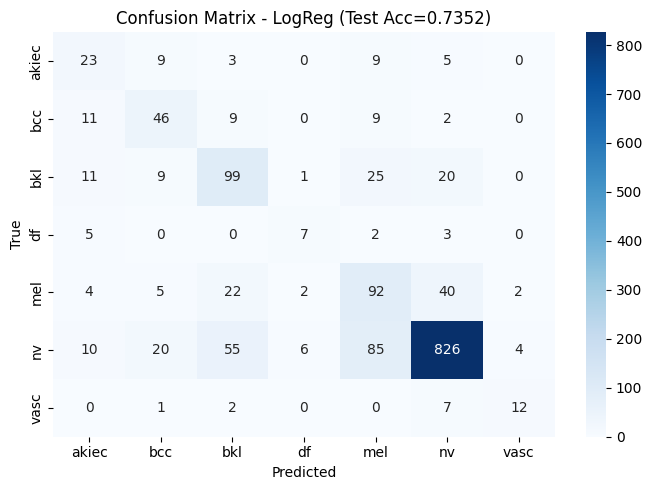


############################################################
🔹 Training: XGBoost
############################################################
Val Accuracy : 0.8090
Test Accuracy: 0.7871

 COMPLETE METRICS SUMMARY - XGBoost
 Accuracy    : 78.71%
 Specificity : 93.11%
 Precision   : 69.25%
 Sensitivity : 46.92%
 F1 Score    : 53.19%

Per-class Specificity:
  akiec : 99.11%
  bcc   : 98.18%
  bkl   : 96.41%
  df    : 99.93%
  mel   : 97.23%
  nv    : 60.97%
  vasc  : 99.93%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.6061    0.4082    0.4878        49
         bcc     0.6061    0.5195    0.5594        77
         bkl     0.6190    0.4727    0.5361       165
          df     0.6667    0.1176    0.2000        17
         mel     0.6064    0.3413    0.4368       167
          nv     0.8342    0.9702    0.8971      1006
        vasc     0.9091    0.4545    0.6061        22

    accuracy                         0.7871      1503
   m

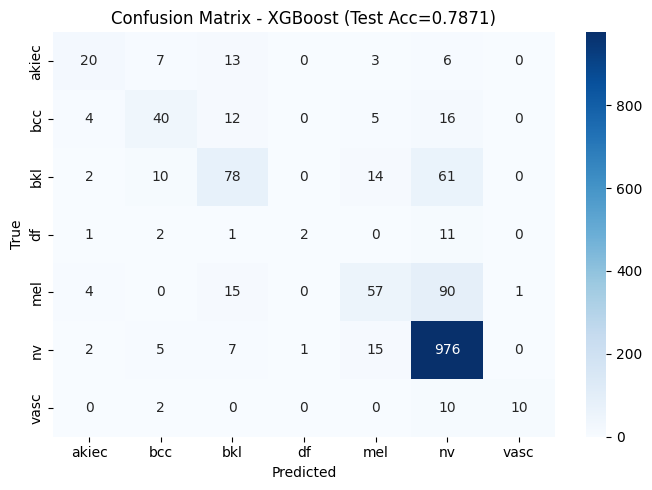


 📊 FINAL COMPARISON - All Classifiers (Test Set)
              Accuracy  Specificity  Precision  Sensitivity     F1
Model                                                             
SVM              81.84        95.06      72.84        57.53  61.76
RandomForest     70.13        87.40      54.44        21.38  23.80
LogReg           73.52        94.44      54.64        57.09  55.40
XGBoost          78.71        93.11      69.25        46.92  53.19

🏆 Best model (by F1): SVM (F1 = 61.76%)

✅ Saved: scaler, models, metrics, summary (seed=2030)


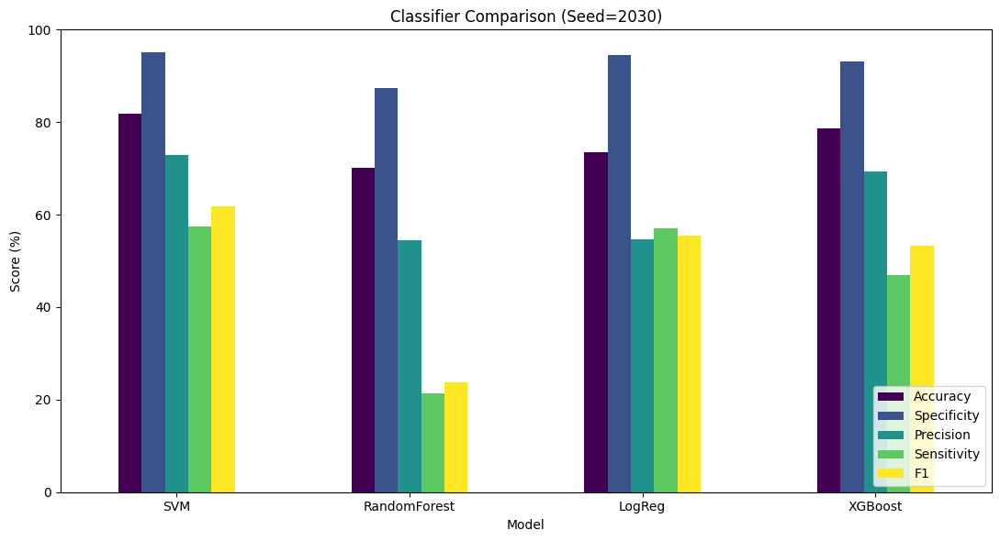

In [20]:
# ================================================================
# 0) تثبيت المكتبات (شغّلها مرة واحدة على Kaggle)
# ================================================================
# !pip install -q xgboost albumentations scikit-image

import os
import random
import numpy as np
import pandas as pd
import cv2
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             f1_score)
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.efficientnet import preprocess_input as ef_preprocess

# ML classifiers
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Handcrafted features
from skimage.feature import local_binary_pattern
from skimage.color import rgb2gray

# إصلاح np.bool لـ numpy 2.x
if not hasattr(np, 'bool'):
    np.bool = bool

# ================================================================
# ⚙️ SEED - غيّره في كل تجربة
# ================================================================
RANDOM_STATE = 2030

os.environ['PYTHONHASHSEED'] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ================================================================
# المسارات والإعدادات
# ================================================================
DATASET_PATH_1 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
DATASET_PATH_2 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2'
METADATA_CSV   = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv'

IMG_SIZE = (224, 224)
BATCH_SIZE = 64
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.7, 0.15, 0.15
USE_HANCRAFTED = True
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-6

# ================================================================
# 1) تحميل الميتاداتا وبناء الـ DataFrame
# ================================================================
meta_df = pd.read_csv(METADATA_CSV)
imageid_to_label = dict(zip(meta_df['image_id'], meta_df['dx']))

image_files_1 = sorted(os.listdir(DATASET_PATH_1))
image_files_2 = sorted(os.listdir(DATASET_PATH_2))
all_image_files = image_files_1 + image_files_2

rows = []
for fname in tqdm(all_image_files, desc='Listing images'):
    image_id = os.path.splitext(fname)[0]
    label = imageid_to_label.get(image_id)
    if label is None:
        continue
    full = os.path.join(DATASET_PATH_1 if fname in image_files_1 else DATASET_PATH_2, fname)
    rows.append((full, label))

df = pd.DataFrame(rows, columns=['path', 'label'])
print("Total images found:", len(df))
print("Label distribution:\n", df['label'].value_counts())

le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))

# ================================================================
# 2) Stratified Split
# ================================================================
train_and_val, test_df = train_test_split(
    df, test_size=TEST_RATIO, stratify=df['label_enc'], random_state=RANDOM_STATE)

relative_val_ratio = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_df, val_df = train_test_split(
    train_and_val, test_size=relative_val_ratio,
    stratify=train_and_val['label_enc'], random_state=RANDOM_STATE)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")

# ================================================================
# 3) Handcrafted Features (LBP + Color Histogram)
# ================================================================
def compute_lbp(img_gray, P=8, R=1):
    lbp = local_binary_pattern(img_gray, P=P, R=R, method='uniform')
    n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(lbp, bins=n_bins, range=(0, n_bins), density=True)
    return hist

def color_histogram(img, n_bins=16):
    chans = cv2.split(img)
    feats = []
    for ch in chans:
        hist, _ = np.histogram(ch, bins=n_bins, range=(0, 256), density=True)
        feats.extend(hist)
    return np.array(feats)

def extract_handcrafted_features(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return np.zeros(26 + 48)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_small = cv2.resize(img, (128, 128))
    gray = rgb2gray(img_small)
    lbp = compute_lbp(gray, P=8, R=1)             # 26 bins
    ch  = color_histogram(img_small, n_bins=16)   # 48 bins
    return np.concatenate([lbp, ch])

# ================================================================
# 4) ConvNeXtTiny Feature Extractor (مجمّد)
# ================================================================
print("\nBuilding ConvNeXtTiny feature extractor...")
base = ConvNeXtTiny(include_top=False,
                    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
                    weights='imagenet')
base.trainable = True
gap = layers.GlobalAveragePooling2D()
feature_model = models.Model(inputs=base.input, outputs=gap(base.output))
feature_model.trainable = False
print("Feature extractor output shape:", feature_model.output_shape)

# ================================================================
# 5) استخراج CNN Features (مرة واحدة فقط)
# ================================================================
def load_image_for_cnn(path):
    img = cv2.imread(path)
    if img is None:
        return np.zeros((IMG_SIZE[0], IMG_SIZE[1], 3), dtype=np.float32)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE)
    return ef_preprocess(img.astype(np.float32))

def extract_cnn_features(df_in, batch_size=BATCH_SIZE, desc="CNN feats"):
    all_feats = []
    for start in tqdm(range(0, len(df_in), batch_size), desc=desc):
        batch_paths = df_in['path'].values[start:start + batch_size]
        batch_imgs  = np.stack([load_image_for_cnn(p) for p in batch_paths], axis=0)
        feats = feature_model.predict(batch_imgs, verbose=0)
        all_feats.append(feats)
    return np.vstack(all_feats)

X_cnn_train = extract_cnn_features(train_df, desc="Train CNN feats")
X_cnn_val   = extract_cnn_features(val_df,   desc="Val CNN feats")
X_cnn_test  = extract_cnn_features(test_df,  desc="Test CNN feats")
print("CNN features shape:", X_cnn_train.shape)

# ================================================================
# 6) استخراج Handcrafted Features
# ================================================================
if USE_HANCRAFTED:
    def compute_features_for_df(df_in, desc):
        return np.vstack([extract_handcrafted_features(p)
                          for p in tqdm(df_in['path'].values, desc=desc)])

    H_train = compute_features_for_df(train_df, "Train handcrafted")
    H_val   = compute_features_for_df(val_df,   "Val handcrafted")
    H_test  = compute_features_for_df(test_df,  "Test handcrafted")

    X_train = np.concatenate([X_cnn_train, H_train], axis=1)
    X_val   = np.concatenate([X_cnn_val,   H_val],   axis=1)
    X_test  = np.concatenate([X_cnn_test,  H_test],  axis=1)
else:
    X_train, X_val, X_test = X_cnn_train, X_cnn_val, X_cnn_test

y_train = train_df['label_enc'].values
y_val   = val_df['label_enc'].values
y_test  = test_df['label_enc'].values

print("Final feature vector shape:", X_train.shape)

# ================================================================
# 7) StandardScaler (مهم لـ SVM / LogReg)
# ================================================================
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# ================================================================
# 8) دالة حساب المقاييس الكاملة
# ================================================================
def compute_full_metrics(y_true, y_pred, class_names, average='macro'):
    """
    تحسب Accuracy, Specificity, Precision, Sensitivity, F1.
    - Specificity: متوسط One-vs-Rest على الفئات.
    - Precision / Sensitivity / F1: عبر sklearn مع average محددة.
    """
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=average, zero_division=0)
    sens = recall_score(y_true, y_pred, average=average, zero_division=0)
    f1   = f1_score(y_true, y_pred, average=average, zero_division=0)

    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    specs = []
    for i in range(len(cm)):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - (tp + fn + fp)
        specs.append(tn / (tn + fp) if (tn + fp) > 0 else 0.0)
    specificity = float(np.mean(specs))

    return {
        'accuracy': acc,
        'specificity': specificity,
        'precision': prec,
        'sensitivity': sens,
        'f1': f1,
        'per_class_specificity': specs,
        'confusion_matrix': cm,
    }


def print_metrics_block(name, m):
    print("\n" + "=" * 50)
    print(f" COMPLETE METRICS SUMMARY - {name}")
    print("=" * 50)
    print(f" Accuracy    : {m['accuracy']*100:.2f}%")
    print(f" Specificity : {m['specificity']*100:.2f}%")
    print(f" Precision   : {m['precision']*100:.2f}%")
    print(f" Sensitivity : {m['sensitivity']*100:.2f}%")
    print(f" F1 Score    : {m['f1']*100:.2f}%")
    print("=" * 50)


def evaluate_model(name, model, Xtr, ytr, Xva, yva, Xte, yte, class_names):
    """يدرب النموذج، يقيّم على Val/Test، يطبع كل المقاييس + Confusion Matrix."""
    print(f"\n{'#'*60}\n🔹 Training: {name}\n{'#'*60}")
    model.fit(Xtr, ytr)

    val_pred  = model.predict(Xva)
    test_pred = model.predict(Xte)

    val_acc  = accuracy_score(yva, val_pred)
    test_acc = accuracy_score(yte, test_pred)
    print(f"Val Accuracy : {val_acc:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")

    # المقاييس الكاملة على Test
    m = compute_full_metrics(yte, test_pred, class_names, average='macro')
    print_metrics_block(name, m)

    # تفصيل لكل فئة
    print("\nPer-class Specificity:")
    for cls, s in zip(class_names, m['per_class_specificity']):
        print(f"  {cls:6s}: {s*100:.2f}%")

    print("\nClassification Report (Test):")
    print(classification_report(yte, test_pred,
                                target_names=class_names, digits=4,
                                zero_division=0))

    # Confusion Matrix
    plt.figure(figsize=(7, 5))
    sns.heatmap(m['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - {name} (Test Acc={test_acc:.4f})")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(f"cm_{name.replace(' ', '_')}_seed{RANDOM_STATE}.png", dpi=150)
    plt.show()
    plt.close()

    return model, m

# ================================================================
# 9) تدريب 4 مصنفات + حساب المقاييس الكاملة
# ================================================================
results  = {}   # النماذج
metrics  = {}   # المقاييس

# --- SVM (RBF) ---
svm = SVC(kernel='rbf', C=10, gamma='scale',
          probability=True, class_weight='balanced',
          random_state=RANDOM_STATE)
results['SVM'], metrics['SVM'] = evaluate_model(
    "SVM", svm, X_train_s, y_train, X_val_s, y_val, X_test_s, y_test, le.classes_)

# --- Random Forest ---
rf = RandomForestClassifier(n_estimators=500, max_depth=None,
                            class_weight='balanced', n_jobs=-1,
                            random_state=RANDOM_STATE)
results['RandomForest'], metrics['RandomForest'] = evaluate_model(
    "RandomForest", rf, X_train, y_train, X_val, y_val, X_test, y_test, le.classes_)

# --- Logistic Regression ---
lr = LogisticRegression(max_iter=2000, class_weight='balanced',
                        n_jobs=-1, random_state=RANDOM_STATE)
results['LogReg'], metrics['LogReg'] = evaluate_model(
    "LogReg", lr, X_train_s, y_train, X_val_s, y_val, X_test_s, y_test, le.classes_)

# --- XGBoost ---
xgb = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6,
                    tree_method='hist', n_jobs=-1,
                    random_state=RANDOM_STATE, eval_metric='mlogloss')
results['XGBoost'], metrics['XGBoost'] = evaluate_model(
    "XGBoost", xgb, X_train, y_train, X_val, y_val, X_test, y_test, le.classes_)

# ================================================================
# 10) جدول المقارنة النهائي
# ================================================================
print("\n" + "=" * 70)
print(" 📊 FINAL COMPARISON - All Classifiers (Test Set)")
print("=" * 70)

summary_rows = []
for name, m in metrics.items():
    summary_rows.append({
        'Model':       name,
        'Accuracy':    m['accuracy']    * 100,
        'Specificity': m['specificity'] * 100,
        'Precision':   m['precision']   * 100,
        'Sensitivity': m['sensitivity'] * 100,
        'F1':          m['f1']          * 100,
    })

summary_df = pd.DataFrame(summary_rows).set_index('Model').round(2)
print(summary_df.to_string())

# أفضل نموذج حسب F1
best_model_name = summary_df['F1'].idxmax()
print(f"\n🏆 Best model (by F1): {best_model_name} "
      f"(F1 = {summary_df.loc[best_model_name, 'F1']:.2f}%)")

# ================================================================
# 11) حفظ كل شيء
# ================================================================
joblib.dump(scaler,  f"scaler_seed{RANDOM_STATE}.pkl")
joblib.dump(results, f"ml_models_seed{RANDOM_STATE}.pkl")
joblib.dump(metrics, f"metrics_seed{RANDOM_STATE}.pkl")
summary_df.to_csv(f"summary_seed{RANDOM_STATE}.csv")
print(f"\n✅ Saved: scaler, models, metrics, summary (seed={RANDOM_STATE})")

# ================================================================
# 12) رسم بياني لمقارنة النماذج
# ================================================================
ax = summary_df.plot(kind='bar', figsize=(11, 6), colormap='viridis')
ax.set_title(f"Classifier Comparison (Seed={RANDOM_STATE})")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.legend(loc='lower right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"comparison_seed{RANDOM_STATE}.png", dpi=150)
plt.show()
plt.close()


🔧 Fitting PCA (95% variance)...
   PCA: 826 -> 276 dims (explained var = 95.02%)

🔧 Fitting LDA...
   LDA: 826 -> 6 dims

🔧 Fitting SelectKBest (k=300)...
   SelectKBest: 826 -> 300 dims

############################################################
🔹 Training: SVM_Scaled
############################################################
Val Accuracy : 0.8337
Test Accuracy: 0.8184

 COMPLETE METRICS SUMMARY - SVM_Scaled
 Accuracy    : 81.84%
 Specificity : 95.06%
 Precision   : 72.84%
 Sensitivity : 57.53%
 F1 Score    : 61.76%

Per-class Specificity:
  akiec : 98.56%
  bcc   : 98.11%
  bkl   : 95.59%
  df    : 99.93%
  mel   : 96.26%
  nv    : 77.06%
  vasc  : 99.93%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.5800    0.5918    0.5859        49
         bcc     0.6582    0.6753    0.6667        77
         bkl     0.6467    0.6545    0.6506       165
          df     0.8000    0.2353    0.3636        17
         mel     0.6124    

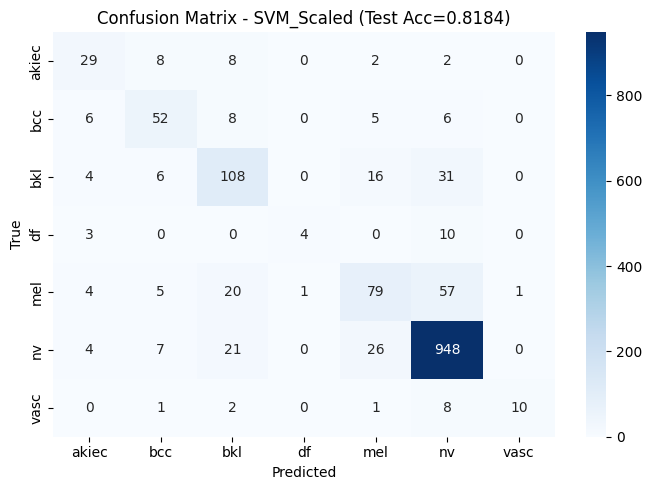


############################################################
🔹 Training: SVM_PCA
############################################################
Val Accuracy : 0.8283
Test Accuracy: 0.8117

 COMPLETE METRICS SUMMARY - SVM_PCA
 Accuracy    : 81.17%
 Specificity : 95.08%
 Precision   : 72.43%
 Sensitivity : 57.34%
 F1 Score    : 61.39%

Per-class Specificity:
  akiec : 98.42%
  bcc   : 98.39%
  bkl   : 94.84%
  df    : 99.93%
  mel   : 95.58%
  nv    : 78.47%
  vasc  : 99.93%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.5577    0.5918    0.5743        49
         bcc     0.6892    0.6623    0.6755        77
         bkl     0.6167    0.6727    0.6435       165
          df     0.8333    0.2941    0.4348        17
         mel     0.5874    0.5030    0.5419       167
          nv     0.8970    0.9264    0.9115      1006
        vasc     0.8889    0.3636    0.5161        22

    accuracy                         0.8117      1503
   m

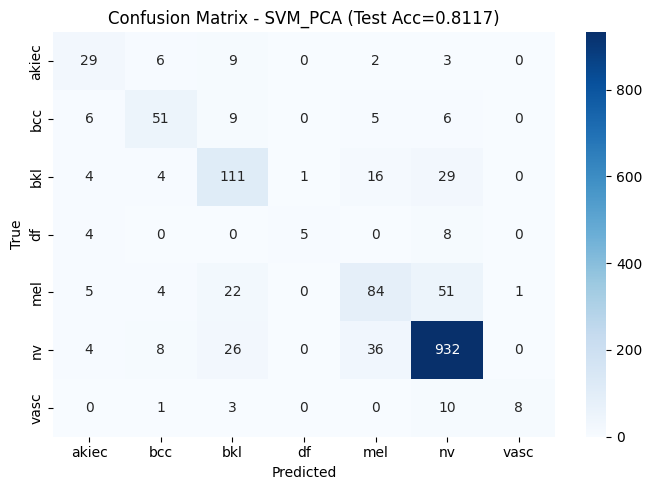


############################################################
🔹 Training: SVM_LDA
############################################################
Val Accuracy : 0.7638
Test Accuracy: 0.7226

 COMPLETE METRICS SUMMARY - SVM_LDA
 Accuracy    : 72.26%
 Specificity : 94.66%
 Precision   : 54.97%
 Sensitivity : 64.47%
 F1 Score    : 58.60%

Per-class Specificity:
  akiec : 97.18%
  bcc   : 96.35%
  bkl   : 93.20%
  df    : 99.39%
  mel   : 88.02%
  nv    : 89.13%
  vasc  : 99.32%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.4605    0.7143    0.5600        49
         bcc     0.4851    0.6364    0.5506        77
         bkl     0.5134    0.5818    0.5455       165
          df     0.4375    0.4118    0.4242        17
         mel     0.3725    0.5689    0.4502       167
          nv     0.9357    0.7813    0.8516      1006
        vasc     0.6429    0.8182    0.7200        22

    accuracy                         0.7226      1503
   m

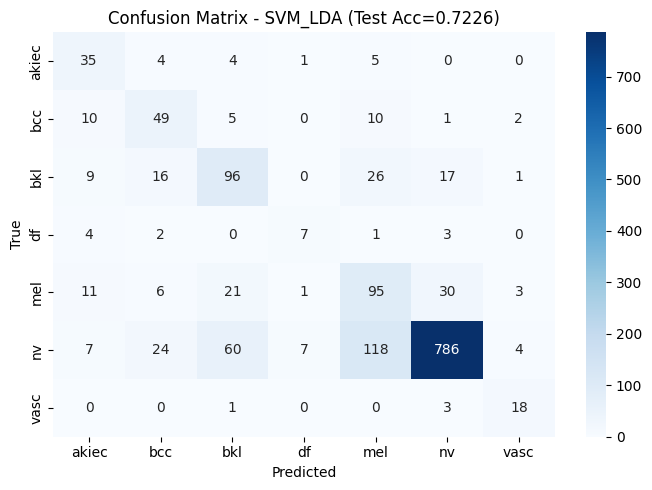


############################################################
🔹 Training: RF_Raw
############################################################
Val Accuracy : 0.7006
Test Accuracy: 0.7013

 COMPLETE METRICS SUMMARY - RF_Raw
 Accuracy    : 70.13%
 Specificity : 87.40%
 Precision   : 54.44%
 Sensitivity : 21.38%
 F1 Score    : 23.80%

Per-class Specificity:
  akiec : 99.79%
  bcc   : 99.93%
  bkl   : 99.70%
  df    : 100.00%
  mel   : 99.33%
  nv    : 13.08%
  vasc  : 100.00%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.7692    0.2041    0.3226        49
         bcc     0.8750    0.0909    0.1647        77
         bkl     0.7778    0.0848    0.1530       165
          df     0.0000    0.0000    0.0000        17
         mel     0.6897    0.1198    0.2041       167
          nv     0.6990    0.9970    0.8218      1006
        vasc     0.0000    0.0000    0.0000        22

    accuracy                         0.7013      1503
   m

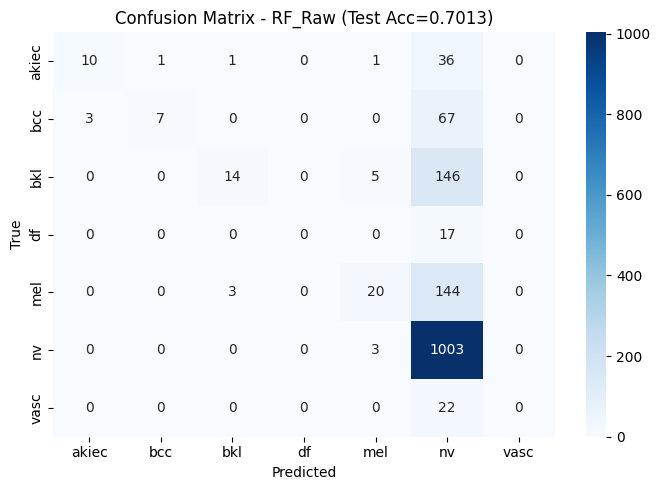


############################################################
🔹 Training: RF_SelectKBest
############################################################
Val Accuracy : 0.7099
Test Accuracy: 0.7119

 COMPLETE METRICS SUMMARY - RF_SelectKBest
 Accuracy    : 71.19%
 Specificity : 88.34%
 Precision   : 47.23%
 Sensitivity : 24.99%
 F1 Score    : 28.34%

Per-class Specificity:
  akiec : 99.31%
  bcc   : 99.58%
  bkl   : 99.33%
  df    : 100.00%
  mel   : 98.65%
  nv    : 21.53%
  vasc  : 100.00%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.5652    0.2653    0.3611        49
         bcc     0.7273    0.2078    0.3232        77
         bkl     0.6786    0.1152    0.1969       165
          df     0.0000    0.0000    0.0000        17
         mel     0.6170    0.1737    0.2710       167
          nv     0.7180    0.9871    0.8313      1006
        vasc     0.0000    0.0000    0.0000        22

    accuracy                         0.711

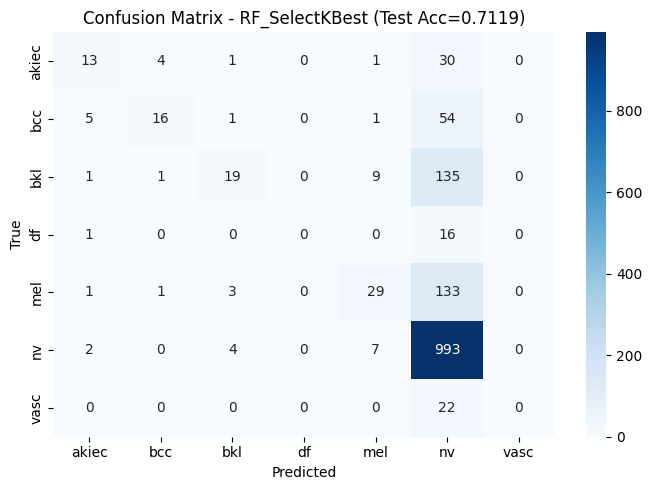


############################################################
🔹 Training: LogReg_Scaled
############################################################
Val Accuracy : 0.7611
Test Accuracy: 0.7352

 COMPLETE METRICS SUMMARY - LogReg_Scaled
 Accuracy    : 73.52%
 Specificity : 94.44%
 Precision   : 54.64%
 Sensitivity : 57.09%
 F1 Score    : 55.40%

Per-class Specificity:
  akiec : 97.18%
  bcc   : 96.91%
  bkl   : 93.20%
  df    : 99.39%
  mel   : 90.27%
  nv    : 84.51%
  vasc  : 99.59%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.3594    0.4694    0.4071        49
         bcc     0.5111    0.5974    0.5509        77
         bkl     0.5211    0.6000    0.5577       165
          df     0.4375    0.4118    0.4242        17
         mel     0.4144    0.5509    0.4730       167
          nv     0.9147    0.8211    0.8654      1006
        vasc     0.6667    0.5455    0.6000        22

    accuracy                         0.7352   

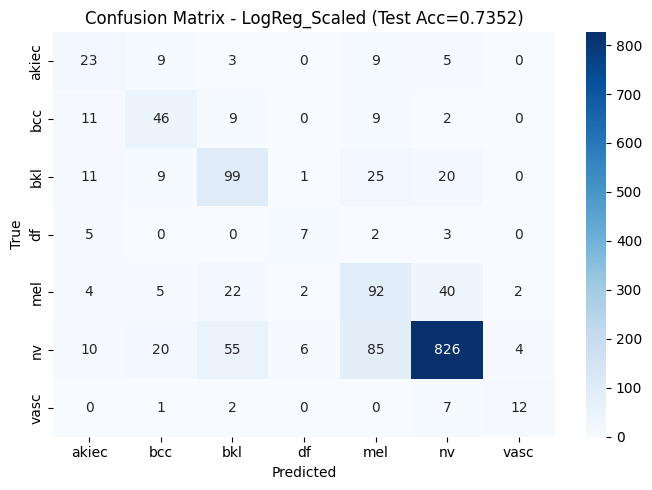


############################################################
🔹 Training: LogReg_PCA
############################################################
Val Accuracy : 0.7212
Test Accuracy: 0.6966

 COMPLETE METRICS SUMMARY - LogReg_PCA
 Accuracy    : 69.66%
 Specificity : 94.41%
 Precision   : 49.01%
 Sensitivity : 60.35%
 F1 Score    : 52.59%

Per-class Specificity:
  akiec : 96.77%
  bcc   : 95.58%
  bkl   : 91.85%
  df    : 97.71%
  mel   : 88.92%
  nv    : 90.54%
  vasc  : 99.46%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.3562    0.5306    0.4262        49
         bcc     0.4220    0.5974    0.4946        77
         bkl     0.4760    0.6000    0.5308       165
          df     0.2273    0.5882    0.3279        17
         mel     0.3884    0.5629    0.4597       167
          nv     0.9417    0.7545    0.8377      1006
        vasc     0.6190    0.5909    0.6047        22

    accuracy                         0.6966      150

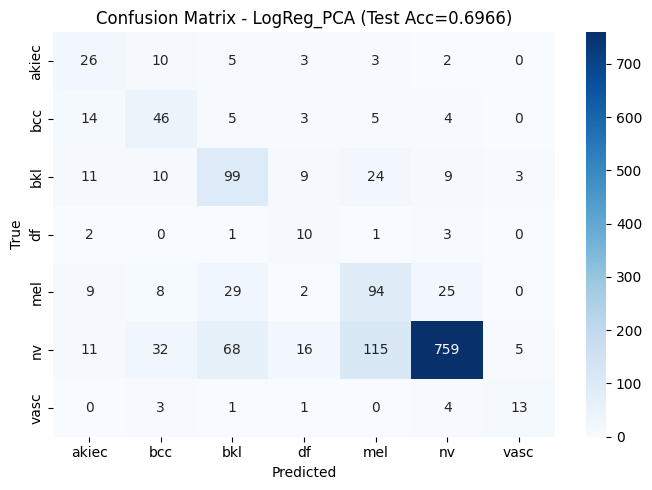


############################################################
🔹 Training: LogReg_LDA
############################################################
Val Accuracy : 0.7598
Test Accuracy: 0.7099

 COMPLETE METRICS SUMMARY - LogReg_LDA
 Accuracy    : 70.99%
 Specificity : 94.54%
 Precision   : 50.14%
 Sensitivity : 65.89%
 F1 Score    : 55.52%

Per-class Specificity:
  akiec : 97.39%
  bcc   : 96.77%
  bkl   : 92.53%
  df    : 97.38%
  mel   : 89.22%
  nv    : 89.74%
  vasc  : 98.78%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.4865    0.7347    0.5854        49
         bcc     0.5054    0.6104    0.5529        77
         bkl     0.5122    0.6364    0.5676       165
          df     0.1702    0.4706    0.2500        17
         mel     0.3846    0.5389    0.4489       167
          nv     0.9373    0.7575    0.8378      1006
        vasc     0.5135    0.8636    0.6441        22

    accuracy                         0.7099      150

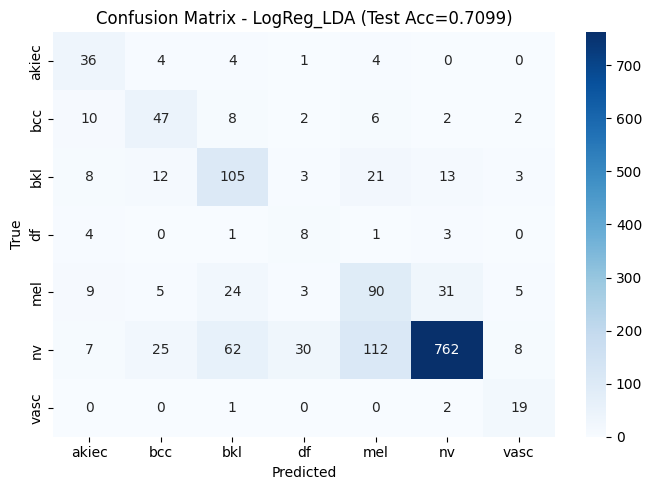


############################################################
🔹 Training: XGB_Raw
############################################################
Val Accuracy : 0.8090
Test Accuracy: 0.7871

 COMPLETE METRICS SUMMARY - XGB_Raw
 Accuracy    : 78.71%
 Specificity : 93.11%
 Precision   : 69.25%
 Sensitivity : 46.92%
 F1 Score    : 53.19%

Per-class Specificity:
  akiec : 99.11%
  bcc   : 98.18%
  bkl   : 96.41%
  df    : 99.93%
  mel   : 97.23%
  nv    : 60.97%
  vasc  : 99.93%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.6061    0.4082    0.4878        49
         bcc     0.6061    0.5195    0.5594        77
         bkl     0.6190    0.4727    0.5361       165
          df     0.6667    0.1176    0.2000        17
         mel     0.6064    0.3413    0.4368       167
          nv     0.8342    0.9702    0.8971      1006
        vasc     0.9091    0.4545    0.6061        22

    accuracy                         0.7871      1503
   m

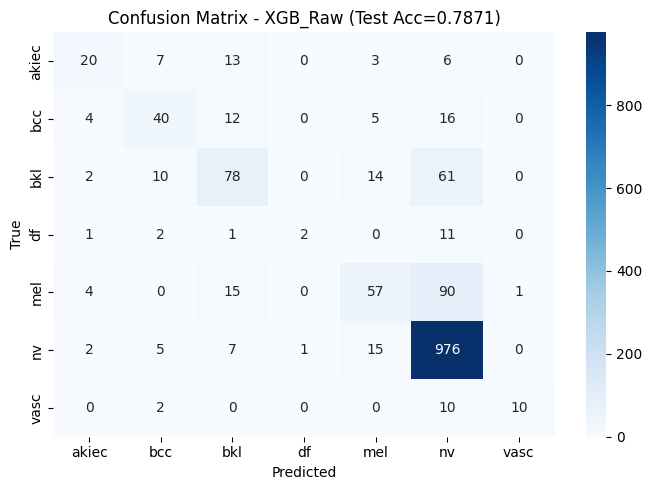


############################################################
🔹 Training: XGB_SelectKBest
############################################################
Val Accuracy : 0.7844
Test Accuracy: 0.7798

 COMPLETE METRICS SUMMARY - XGB_SelectKBest
 Accuracy    : 77.98%
 Specificity : 92.98%
 Precision   : 64.55%
 Sensitivity : 44.70%
 F1 Score    : 50.22%

Per-class Specificity:
  akiec : 98.76%
  bcc   : 98.18%
  bkl   : 96.49%
  df    : 99.93%
  mel   : 96.78%
  nv    : 60.76%
  vasc  : 99.93%

Classification Report (Test):
              precision    recall  f1-score   support

       akiec     0.4857    0.3469    0.4048        49
         bcc     0.5806    0.4675    0.5180        77
         bkl     0.6240    0.4727    0.5379       165
          df     0.5000    0.0588    0.1053        17
         mel     0.5865    0.3653    0.4502       167
          nv     0.8325    0.9632    0.8931      1006
        vasc     0.9091    0.4545    0.6061        22

    accuracy                         0.779

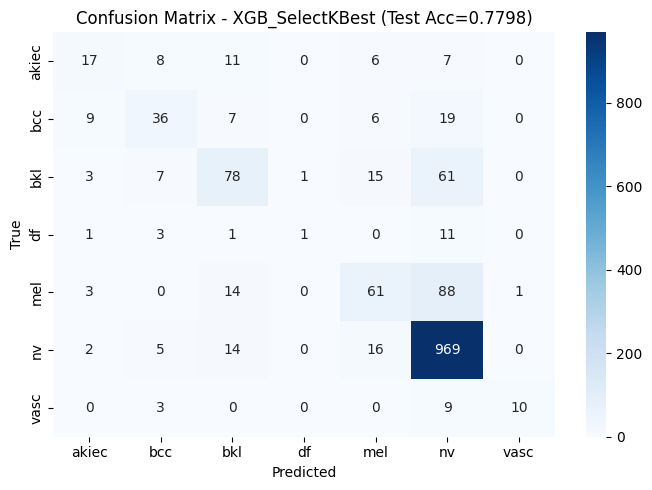


 📊 FINAL COMPARISON - All Classifier × Representation (Test Set)
                 Accuracy  Specificity  Precision  Sensitivity     F1
Model                                                                
SVM_Scaled          81.84        95.06      72.84        57.53  61.76
SVM_PCA             81.17        95.08      72.43        57.34  61.39
SVM_LDA             72.26        94.66      54.97        64.47  58.60
LogReg_LDA          70.99        94.54      50.14        65.89  55.52
LogReg_Scaled       73.52        94.44      54.64        57.09  55.40
XGB_Raw             78.71        93.11      69.25        46.92  53.19
LogReg_PCA          69.66        94.41      49.01        60.35  52.59
XGB_SelectKBest     77.98        92.98      64.55        44.70  50.22
RF_SelectKBest      71.19        88.34      47.23        24.99  28.34
RF_Raw              70.13        87.40      54.44        21.38  23.80

🏆 Best model (by F1): SVM_Scaled (F1 = 61.76%, Acc = 81.84%)

✅ Saved: scaler, PCA, LDA, Sele

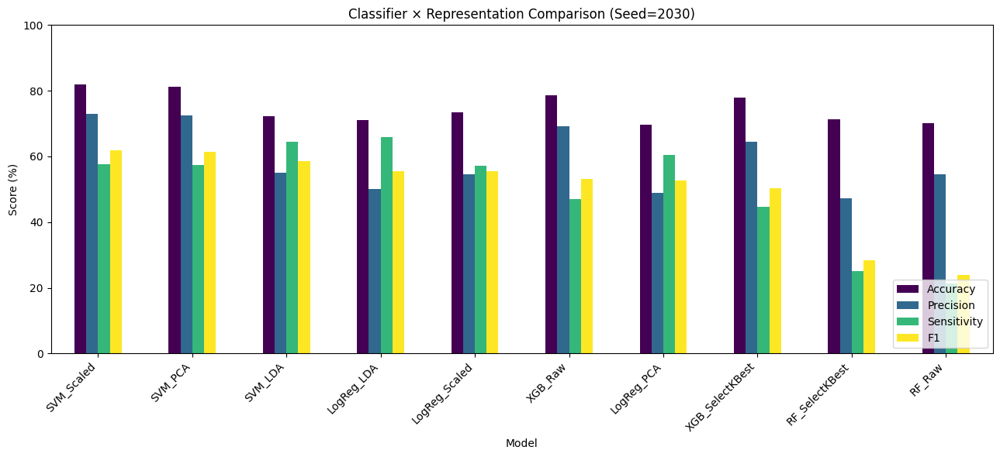

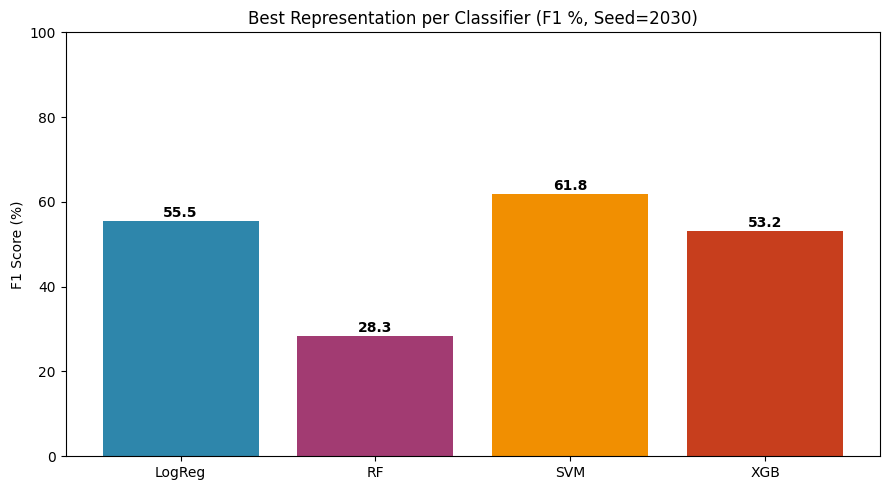


📌 Best representation per base model:
BaseModel          Model    F1  Accuracy
   LogReg     LogReg_LDA 55.52     70.99
       RF RF_SelectKBest 28.34     71.19
      SVM     SVM_Scaled 61.76     81.84
      XGB        XGB_Raw 53.19     78.71


In [21]:
# ================================================================
# 7) StandardScaler + تقليل الأبعاد (PCA / LDA / SelectKBest)
# ================================================================
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import SelectKBest, f_classif

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# --- PCA: نحتفظ بـ 95% من التباين (أو 256 مكوّن كحد أقصى) ---
print("\n🔧 Fitting PCA (95% variance)...")
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_s)
X_val_pca   = pca.transform(X_val_s)
X_test_pca  = pca.transform(X_test_s)
print(f"   PCA: {X_train_s.shape[1]} -> {X_train_pca.shape[1]} dims "
      f"(explained var = {pca.explained_variance_ratio_.sum()*100:.2f}%)")

# --- LDA: حتى num_classes-1 مكوّن (6 لـ 7 فئات) ---
print("\n🔧 Fitting LDA...")
lda = LinearDiscriminantAnalysis(n_components=num_classes - 1)
X_train_lda = lda.fit_transform(X_train_s, y_train)
X_val_lda   = lda.transform(X_val_s)
X_test_lda  = lda.transform(X_test_s)
print(f"   LDA: {X_train_s.shape[1]} -> {X_train_lda.shape[1]} dims")

# --- SelectKBest: نحتفظ بأفضل 300 feature ---
K_BEST = min(300, X_train_s.shape[1])
print(f"\n🔧 Fitting SelectKBest (k={K_BEST})...")
skb = SelectKBest(score_func=f_classif, k=K_BEST)
X_train_skb = skb.fit_transform(X_train_s, y_train)
X_val_skb   = skb.transform(X_val_s)
X_test_skb  = skb.transform(X_test_s)
print(f"   SelectKBest: {X_train_s.shape[1]} -> {X_train_skb.shape[1]} dims")

# ================================================================
# 8) دالة حساب المقاييس الكاملة (كما هي)
# ================================================================
def compute_full_metrics(y_true, y_pred, class_names, average='macro'):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=average, zero_division=0)
    sens = recall_score(y_true, y_pred, average=average, zero_division=0)
    f1   = f1_score(y_true, y_pred, average=average, zero_division=0)

    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    specs = []
    for i in range(len(cm)):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - (tp + fn + fp)
        specs.append(tn / (tn + fp) if (tn + fp) > 0 else 0.0)
    specificity = float(np.mean(specs))

    return {
        'accuracy': acc, 'specificity': specificity,
        'precision': prec, 'sensitivity': sens, 'f1': f1,
        'per_class_specificity': specs, 'confusion_matrix': cm,
    }


def print_metrics_block(name, m):
    print("\n" + "=" * 50)
    print(f" COMPLETE METRICS SUMMARY - {name}")
    print("=" * 50)
    print(f" Accuracy    : {m['accuracy']*100:.2f}%")
    print(f" Specificity : {m['specificity']*100:.2f}%")
    print(f" Precision   : {m['precision']*100:.2f}%")
    print(f" Sensitivity : {m['sensitivity']*100:.2f}%")
    print(f" F1 Score    : {m['f1']*100:.2f}%")
    print("=" * 50)


def evaluate_model(name, model, Xtr, ytr, Xva, yva, Xte, yte, class_names):
    print(f"\n{'#'*60}\n🔹 Training: {name}\n{'#'*60}")
    model.fit(Xtr, ytr)
    val_pred  = model.predict(Xva)
    test_pred = model.predict(Xte)

    val_acc  = accuracy_score(yva, val_pred)
    test_acc = accuracy_score(yte, test_pred)
    print(f"Val Accuracy : {val_acc:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")

    m = compute_full_metrics(yte, test_pred, class_names, average='macro')
    print_metrics_block(name, m)

    print("\nPer-class Specificity:")
    for cls, s in zip(class_names, m['per_class_specificity']):
        print(f"  {cls:6s}: {s*100:.2f}%")

    print("\nClassification Report (Test):")
    print(classification_report(yte, test_pred, target_names=class_names,
                                digits=4, zero_division=0))

    plt.figure(figsize=(7, 5))
    sns.heatmap(m['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - {name} (Test Acc={test_acc:.4f})")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(f"cm_{name.replace(' ', '_')}_seed{RANDOM_STATE}.png", dpi=150)
    plt.show(); plt.close()
    return model, m

# ================================================================
# 9) تدريب المصنفات على كل تمثيل (Baseline / PCA / LDA / SelectKBest)
# ================================================================
results = {}
metrics = {}

representations = {
    "Raw":         (X_train,     X_val,     X_test),      # بدون scaling (RF/XGB)
    "Scaled":      (X_train_s,   X_val_s,   X_test_s),    # scaled (SVM/LogReg)
    "PCA":         (X_train_pca, X_val_pca, X_test_pca),
    "LDA":         (X_train_lda, X_val_lda, X_test_lda),
    "SelectKBest": (X_train_skb, X_val_skb, X_test_skb),
}

# --- SVM: يفضل Scaled / PCA / LDA ---
for rep_name in ["Scaled", "PCA", "LDA"]:
    Xtr, Xva, Xte = representations[rep_name]
    key = f"SVM_{rep_name}"
    svm = SVC(kernel='rbf', C=10, gamma='scale',
              probability=True, class_weight='balanced',
              random_state=RANDOM_STATE)
    results[key], metrics[key] = evaluate_model(
        key, svm, Xtr, y_train, Xva, y_val, Xte, y_test, le.classes_)

# --- Random Forest: يفضل Raw / SelectKBest ---
for rep_name in ["Raw", "SelectKBest"]:
    Xtr, Xva, Xte = representations[rep_name]
    key = f"RF_{rep_name}"
    rf = RandomForestClassifier(n_estimators=500, max_depth=None,
                                class_weight='balanced', n_jobs=-1,
                                random_state=RANDOM_STATE)
    results[key], metrics[key] = evaluate_model(
        key, rf, Xtr, y_train, Xva, y_val, Xte, y_test, le.classes_)

# --- Logistic Regression: يفضل Scaled / PCA / LDA ---
for rep_name in ["Scaled", "PCA", "LDA"]:
    Xtr, Xva, Xte = representations[rep_name]
    key = f"LogReg_{rep_name}"
    lr = LogisticRegression(max_iter=2000, class_weight='balanced',
                            n_jobs=-1, random_state=RANDOM_STATE)
    results[key], metrics[key] = evaluate_model(
        key, lr, Xtr, y_train, Xva, y_val, Xte, y_test, le.classes_)

# --- XGBoost: يفضل Raw / SelectKBest ---
for rep_name in ["Raw", "SelectKBest"]:
    Xtr, Xva, Xte = representations[rep_name]
    key = f"XGB_{rep_name}"
    xgb = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6,
                        tree_method='hist', n_jobs=-1,
                        random_state=RANDOM_STATE, eval_metric='mlogloss')
    results[key], metrics[key] = evaluate_model(
        key, xgb, Xtr, y_train, Xva, y_val, Xte, y_test, le.classes_)

# ================================================================
# 10) جدول المقارنة النهائي (مرتّب حسب F1)
# ================================================================
print("\n" + "=" * 80)
print(" 📊 FINAL COMPARISON - All Classifier × Representation (Test Set)")
print("=" * 80)

summary_rows = []
for name, m in metrics.items():
    summary_rows.append({
        'Model':       name,
        'Accuracy':    m['accuracy']    * 100,
        'Specificity': m['specificity'] * 100,
        'Precision':   m['precision']   * 100,
        'Sensitivity': m['sensitivity'] * 100,
        'F1':          m['f1']          * 100,
    })

summary_df = pd.DataFrame(summary_rows).set_index('Model').round(2)
summary_df = summary_df.sort_values('F1', ascending=False)
print(summary_df.to_string())

best_model_name = summary_df['F1'].idxmax()
print(f"\n🏆 Best model (by F1): {best_model_name} "
      f"(F1 = {summary_df.loc[best_model_name, 'F1']:.2f}%, "
      f"Acc = {summary_df.loc[best_model_name, 'Accuracy']:.2f}%)")

# ================================================================
# 11) حفظ كل شيء (بما فيه المحوّلات)
# ================================================================
joblib.dump(scaler, f"scaler_seed{RANDOM_STATE}.pkl")
joblib.dump(pca,    f"pca_seed{RANDOM_STATE}.pkl")
joblib.dump(lda,    f"lda_seed{RANDOM_STATE}.pkl")
joblib.dump(skb,    f"selectkbest_seed{RANDOM_STATE}.pkl")
joblib.dump(results, f"ml_models_seed{RANDOM_STATE}.pkl")
joblib.dump(metrics, f"metrics_seed{RANDOM_STATE}.pkl")
summary_df.to_csv(f"summary_seed{RANDOM_STATE}.csv")
print(f"\n✅ Saved: scaler, PCA, LDA, SelectKBest, models, metrics, summary "
      f"(seed={RANDOM_STATE})")

# ================================================================
# 12) رسوم بيانية للمقارنة
# ================================================================
# (أ) bar chart لكل النماذج
ax = summary_df[['Accuracy', 'Precision', 'Sensitivity', 'F1']].plot(
    kind='bar', figsize=(13, 6), colormap='viridis')
ax.set_title(f"Classifier × Representation Comparison (Seed={RANDOM_STATE})")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.legend(loc='lower right')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f"comparison_seed{RANDOM_STATE}.png", dpi=150)
plt.show(); plt.close()

# (ب) أفضل تمثيل لكل مصنف
best_per_model = summary_df.reset_index()
best_per_model['BaseModel'] = best_per_model['Model'].str.split('_').str[0]
best_per_model = best_per_model.loc[
    best_per_model.groupby('BaseModel')['F1'].idxmax()]

plt.figure(figsize=(9, 5))
plt.bar(best_per_model['BaseModel'], best_per_model['F1'],
        color=['#2E86AB', '#A23B72', '#F18F01', '#C73E1D'])
plt.title(f"Best Representation per Classifier (F1 %, Seed={RANDOM_STATE})")
plt.ylabel("F1 Score (%)")
plt.ylim(0, 100)
for i, v in enumerate(best_per_model['F1']):
    plt.text(i, v + 1, f"{v:.1f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(f"best_per_model_seed{RANDOM_STATE}.png", dpi=150)
plt.show(); plt.close()

print("\n📌 Best representation per base model:")
print(best_per_model[['BaseModel', 'Model', 'F1', 'Accuracy']].to_string(index=False))

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

pipe_lda_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=6)),
    ('svm', SVC(kernel='rbf', C=10, gamma='scale',
                probability=True, class_weight='balanced',
                random_state=RANDOM_STATE))
])
pipe_lda_svm.fit(X_train, y_train)
y_pred = pipe_lda_svm.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

              precision    recall  f1-score   support

       akiec     0.4605    0.7143    0.5600        49
         bcc     0.4851    0.6364    0.5506        77
         bkl     0.5134    0.5818    0.5455       165
          df     0.4375    0.4118    0.4242        17
         mel     0.3725    0.5689    0.4502       167
          nv     0.9357    0.7813    0.8516      1006
        vasc     0.6429    0.8182    0.7200        22

    accuracy                         0.7226      1503
   macro avg     0.5497    0.6447    0.5860      1503
weighted avg     0.7783    0.7226    0.7417      1503

